# Week 7 Take Home

This week has two parts. Complete **both**.

| Part | Lessons | Project |
|------|---------|---------|
| **A. Cleaning & Visualising Data** | `1-Cleaning & Visualising Data/` | Holiday weather |
| **B. Transforming & Combining Data** | `2-Transforming & Combining Data/` | GDP and life expectancy + your own World Bank project |

Data for both parts comes from the cohort database (schemas `week07` and `week08`). See `Data Access (SQL).md`.

---
# Part A: Cleaning & Visualising Data

### Solve `1-Cleaning & Visualising Data/1.ipynb` Tasks Below

In [ ]:
import sys, pathlib
import pandas as pd
from datetime import datetime

# Find the project root so Python can import the db helper
_p = pathlib.Path.cwd()
while _p != _p.parent and not (_p / "db" / "dataraflow_db.py").exists():
    _p = _p.parent
sys.path.insert(0, str(_p))
from db.dataraflow_db import run_query

%matplotlib inline

In [ ]:
london = run_query("SELECT * FROM week07.london_2014")
london.to_csv("london_2014_raw.csv", index=False)   # offline backup
print(london.shape)
print(london.columns.tolist())

(365, 23)
['GMT', 'Max TemperatureC', 'Mean TemperatureC', 'Min TemperatureC', 'Dew PointC', 'MeanDew PointC', 'Min DewpointC', 'Max Humidity', ' Mean Humidity', ' Min Humidity', ' Max Sea Level PressurehPa', ' Mean Sea Level PressurehPa', ' Min Sea Level PressurehPa', ' Max VisibilityKm', ' Mean VisibilityKm', ' Min VisibilitykM', ' Max Wind SpeedKm/h', ' Mean Wind SpeedKm/h', ' Max Gust SpeedKm/h', 'Precipitationmm', ' CloudCover', ' Events', 'WindDirDegrees<br />']


In [ ]:
london.head()

,GMT,Max TemperatureC,Mean TemperatureC,Min TemperatureC,Dew PointC,MeanDew PointC,Min DewpointC,Max Humidity,Mean Humidity,Min Humidity,...,Max VisibilityKm,Mean VisibilityKm,Min VisibilitykM,Max Wind SpeedKm/h,Mean Wind SpeedKm/h,Max Gust SpeedKm/h,Precipitationmm,CloudCover,Events,WindDirDegrees<br />
0,2014-1-1,11,8,6,9,7,4,94,86,73,...,31,11,2,40,26,66.0,9.91,4.0,Rain,186<br />
1,2014-1-2,11,9,6,9,6,4,94,81,60,...,31,15,5,32,21,50.0,1.02,2.0,Rain,214<br />
2,2014-1-3,11,8,6,9,5,2,94,76,54,...,31,12,0,50,29,69.0,7.11,2.0,Rain-Thunderstorm,219<br />
3,2014-1-4,9,6,3,8,6,2,93,85,65,...,31,12,5,35,21,39.0,9.91,4.0,Rain,211<br />
4,2014-1-5,12,7,1,11,4,-1,100,88,77,...,31,14,5,35,16,NaN,0.25,5.0,Rain,199<br />


In [ ]:
# Remove leading and trailing spaces from the column names
london.columns = london.columns.str.strip()

# Fix the last column's name, then remove <br /> from its values
london = london.rename(columns={"WindDirDegrees<br />": "WindDirDegrees"})
london["WindDirDegrees"] = london["WindDirDegrees"].astype(str).str.replace("<br />", "", regex=False)
london["WindDirDegrees"] = london["WindDirDegrees"].astype(int)

# Dates are text; convert them to real dates
london["GMT"] = pd.to_datetime(london["GMT"])

# Blank events become empty text, as in the lesson
london["Events"] = london["Events"].fillna("")

print(london.dtypes)

GMT                           datetime64[us]
Max TemperatureC                       int64
Mean TemperatureC                      int64
Min TemperatureC                       int64
Dew PointC                             int64
MeanDew PointC                         int64
Min DewpointC                          int64
Max Humidity                           int64
Mean Humidity                          int64
Min Humidity                           int64
Max Sea Level PressurehPa              int64
Mean Sea Level PressurehPa             int64
Min Sea Level PressurehPa              int64
Max VisibilityKm                       int64
Mean VisibilityKm                      int64
Min VisibilitykM                       int64
Max Wind SpeedKm/h                     int64
Mean Wind SpeedKm/h                    int64
Max Gust SpeedKm/h                   float64
Precipitationmm                      float64
CloudCover                           float64
Events                                   str
WindDirDeg

1. Now that the wind direction is given by a number, write code to select all days that had a northerly wind. Hint: select the rows where the direction is greater than or equal to 350 or smaller than or equal to 10, as the compass rose shows.

In [ ]:
northerly_wind_days = london[(london['WindDirDegrees'] >= 350) | (london['WindDirDegrees'] <= 10)]

northerly_wind_days

,GMT,Max TemperatureC,Mean TemperatureC,Min TemperatureC,Dew PointC,MeanDew PointC,Min DewpointC,Max Humidity,Mean Humidity,Min Humidity,...,Max VisibilityKm,Mean VisibilityKm,Min VisibilitykM,Max Wind SpeedKm/h,Mean Wind SpeedKm/h,Max Gust SpeedKm/h,Precipitationmm,CloudCover,Events,WindDirDegrees
84,2014-03-26,9,6,2,4,2,-1,100,80,39,...,27,10,1,26,10,NaN,2.03,4.0,Fog-Rain,3
90,2014-04-01,19,13,7,11,9,6,100,80,39,...,19,7,0,16,5,NaN,0.00,4.0,Fog-Rain,6
100,2014-04-11,16,12,9,5,4,2,71,53,28,...,31,18,10,13,8,NaN,0.00,1.0,,351
110,2014-04-21,19,12,5,11,8,4,100,78,31,...,26,7,0,14,6,NaN,9.91,3.0,Fog-Rain-Thunderstorm,356
174,2014-06-24,24,19,13,15,12,9,94,66,27,...,31,12,0,23,8,37.0,0.00,3.0,Fog,350
179,2014-06-29,19,16,12,11,9,5,88,65,31,...,31,16,10,19,10,NaN,0.00,2.0,Rain,9
190,2014-07-10,22,18,14,13,11,9,82,64,44,...,31,19,10,16,14,NaN,0.00,3.0,,1
208,2014-07-28,23,19,14,16,12,9,94,66,33,...,26,12,2,21,10,NaN,17.02,2.0,Rain-Thunderstorm,3
249,2014-09-07,21,17,13,14,12,8,94,71,41,...,23,10,2,11,6,NaN,0.00,4.0,,354
250,2014-09-08,22,16,10,13,9,7,94,64,28,...,27,12,5,11,6,NaN,0.00,1.0,,351


2. In the code cell below, write code to get and display all the rows in the dataframe that are beween 1 April 2014 and 11 April 2014.

In [ ]:
dates = london['GMT']
start = datetime(2014, 4, 1)
end = datetime(2014, 4, 11)
days_df = london[(dates >= start) & (dates <= end)]
days_df

,GMT,Max TemperatureC,Mean TemperatureC,Min TemperatureC,Dew PointC,MeanDew PointC,Min DewpointC,Max Humidity,Mean Humidity,Min Humidity,...,Max VisibilityKm,Mean VisibilityKm,Min VisibilitykM,Max Wind SpeedKm/h,Mean Wind SpeedKm/h,Max Gust SpeedKm/h,Precipitationmm,CloudCover,Events,WindDirDegrees
90,2014-04-01,19,13,7,11,9,6,100,80,39,...,19,7,0,16,5,NaN,0.00,4.0,Fog-Rain,6
91,2014-04-02,18,14,11,11,9,7,88,71,48,...,10,8,5,23,13,NaN,0.00,1.0,Rain,85
92,2014-04-03,18,14,11,11,9,9,88,75,52,...,21,7,3,26,11,NaN,0.00,5.0,,96
93,2014-04-04,15,12,9,10,8,6,88,71,46,...,31,11,2,24,14,NaN,0.00,5.0,,253
94,2014-04-05,14,10,6,11,8,5,100,83,56,...,31,12,1,26,13,50.0,0.00,5.0,Fog-Rain,197
95,2014-04-06,16,14,12,12,12,11,94,88,67,...,31,12,5,35,21,48.0,2.03,6.0,Rain,213
96,2014-04-07,14,11,8,12,11,6,94,87,76,...,31,14,5,29,23,42.0,2.03,5.0,Rain,209
97,2014-04-08,14,9,5,6,3,-1,87,64,26,...,31,15,10,39,23,NaN,0.00,2.0,Rain,269
98,2014-04-09,17,10,4,7,6,3,93,68,38,...,31,14,6,23,13,NaN,0.00,2.0,,261
99,2014-04-10,16,11,6,6,5,3,93,62,31,...,31,14,9,19,10,NaN,0.00,3.0,,278


3. In the cell below, write two lines of code to display the first five rows that have a missing value in the `'Max Gust SpeedKm/h'` column.
Hint: first select the missing value rows and store them in a new dataframe, then display the first five rows of the new dataframe.

In [ ]:
missing_gust = london['Max Gust SpeedKm/h'].isnull()
london[missing_gust].head(5)

,GMT,Max TemperatureC,Mean TemperatureC,Min TemperatureC,Dew PointC,MeanDew PointC,Min DewpointC,Max Humidity,Mean Humidity,Min Humidity,...,Max VisibilityKm,Mean VisibilityKm,Min VisibilitykM,Max Wind SpeedKm/h,Mean Wind SpeedKm/h,Max Gust SpeedKm/h,Precipitationmm,CloudCover,Events,WindDirDegrees
4,2014-01-05,12,7,1,11,4,-1,100,88,77,...,31,14,5,35,16,NaN,0.25,5.0,Rain,199
10,2014-01-11,9,4,0,7,3,-1,100,80,51,...,31,12,6,24,14,NaN,0.00,4.0,Rain,259
11,2014-01-12,10,4,-2,9,3,-2,100,91,79,...,31,9,1,32,10,NaN,0.51,6.0,Fog-Rain,126
12,2014-01-13,9,7,5,8,4,3,93,85,71,...,31,16,5,34,19,NaN,5.08,2.0,Rain,205
13,2014-01-14,7,4,1,5,2,0,100,82,55,...,31,15,10,21,13,NaN,0.25,3.0,Rain,242


### Solve `1-Cleaning & Visualising Data/2.ipynb` Tasks Below

1. In the cell below, write code to plot the minimum, mean, and maximum temperature during 2014 in London.

<Axes: >

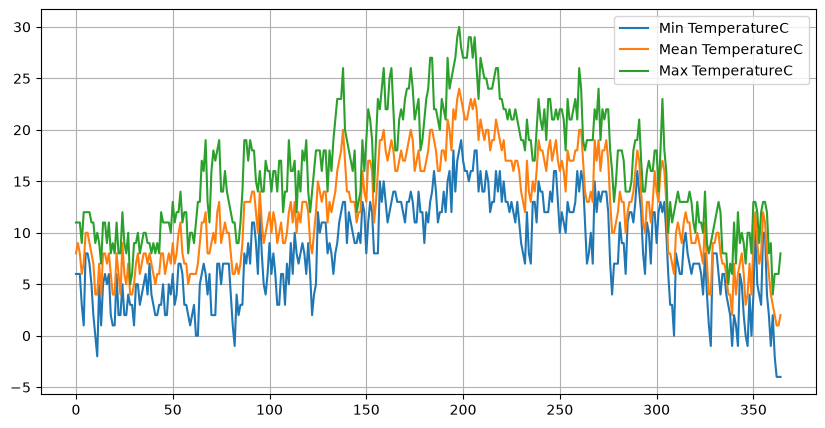

In [ ]:
london[['Min TemperatureC', 'Mean TemperatureC', 'Max TemperatureC']].plot(grid=True, figsize=(10,5))

2. Use the code cell below to plot the values of  `'Mean Humidity'` during spring (full months of March, April and May).

In [ ]:
london.index = london['GMT']
london =london.sort_index()

<Axes: xlabel='GMT'>

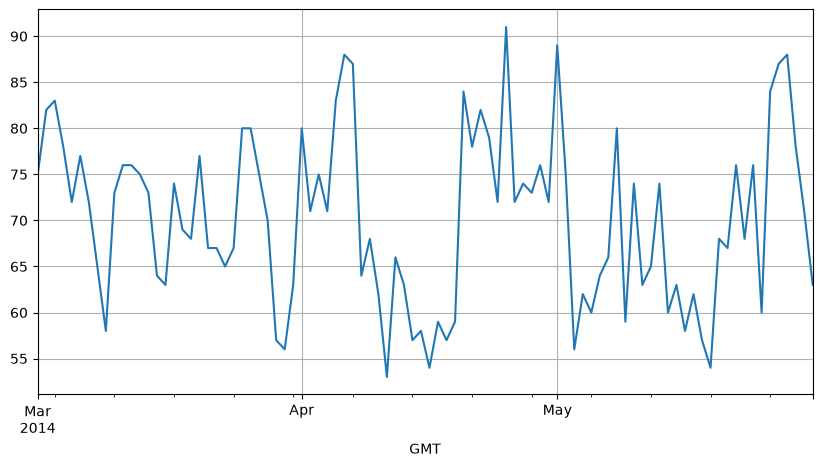

In [ ]:
london['Mean Humidity'].loc[datetime(2014, 3, 1) : datetime(2014, 5, 31)].plot(grid=True, figsize=(10,5))

## Project A: Holiday weather


There is nothing I like better than taking a holiday. In this project I am going to use the historic weather data from the Weather Underground for London to try to predict two good weather weeks to take off as holiday. Of course the weather in the summer of 2025 may be very different to 2020 but it should give some indication of when would be a good time to take a summer break.

## Getting the data

Weather Underground keeps historical weather data collected in many airports around the world. Right-click on the following URL and choose 'Open Link in New Window' (or similar, depending on your browser):

http://www.wunderground.com/history

When the new page opens start typing 'LHR' in the 'Location' input box and when the pop up menu comes up with the option 'LHR, United Kingdom' select it and then click on 'Submit'.

When the next page opens with London Heathrow data, click on the 'Custom' tab and select the time period From: 1 January 2023 to: 31 December 2023 and then click on 'Get History'. The data for that year should then be displayed further down the page.

You can copy each month's data directly from the browser to a text editor like Notepad or TextEdit, to obtain a single file with as many months as you wish.


Now load the CSV file into a dataframe making sure that any extra spaces are skipped:

### Step-1 Cleaning the data


In [ ]:
%matplotlib inline

In [ ]:
#Loading the data
lhr = pd.read_csv("london_lhr_2023.csv", skipinitialspace=True)
lhr.head()

,Date,Temperature (C) Max,Temperature (C) Avg,Temperature (C) Min,Dew Point (C) Max,Dew Point (C) Avg,Dew Point (C) Min,Humidity (%) Max,Humidity (%) Avg,Humidity (%) Min,Wind Speed (km/h) Max,Wind Speed (km/h) Avg,Wind Speed (km/h) Min,Pressure (hPa) Max,Pressure (hPa) Avg,Pressure (hPa) Min,Precipitation (mm)
0,1/1/2023,12,10.4,7,9,7.1,6,93,80.1,71,31,18.5,4,1007.0,1004.9,1000.0,0
1,1/2/2023,8,5.8,2,6,3.7,1,100,87.0,70,19,10.4,2,1020.0,1013.9,1006.0,0
2,1/3/2023,13,8.8,3,11,7.5,2,100,92.2,87,33,20.1,0,1019.0,1014.9,1010.0,0
3,1/4/2023,14,12.5,11,11,9.1,7,94,80.2,67,44,30.2,19,1016.0,1011.4,1009.0,0
4,1/5/2023,14,11.5,10,10,8.4,7,94,81.5,72,28,20.7,13,1017.0,1015.1,1010.0,0


In [ ]:

# Quick check of the shape and column names
print("Shape: ", lhr.shape)
print("Columns: ", lhr.columns.tolist())

Shape:  (365, 17)
Columns:  ['Date', 'Temperature (C) Max', 'Temperature (C) Avg', 'Temperature (C) Min', 'Dew Point (C) Max', 'Dew Point (C) Avg', 'Dew Point (C) Min', 'Humidity (%) Max', 'Humidity (%) Avg', 'Humidity (%) Min', 'Wind Speed (km/h) Max', 'Wind Speed (km/h) Avg', 'Wind Speed (km/h) Min', 'Pressure (hPa) Max', 'Pressure (hPa) Avg', 'Pressure (hPa) Min', 'Precipitation (mm)']


In [ ]:
lhr = lhr.rename(columns={
    'Temperature (C) Max': 'temp_max',
    'Temperature (C) Avg': 'temp_avg',
    'Wind Speed (km/h) Avg': 'wind_avg',
    'Humidity (%) Avg': 'humidity_avg'
})

In [ ]:
# column types
print(lhr.dtypes)

Date                         str
temp_max                   int64
temp_avg                 float64
Temperature (C) Min        int64
Dew Point (C) Max          int64
Dew Point (C) Avg        float64
Dew Point (C) Min          int64
Humidity (%) Max           int64
humidity_avg             float64
Humidity (%) Min           int64
Wind Speed (km/h) Max      int64
wind_avg                 float64
Wind Speed (km/h) Min      int64
Pressure (hPa) Max       float64
Pressure (hPa) Avg       float64
Pressure (hPa) Min       float64
Precipitation (mm)         int64
dtype: object


In [ ]:
print(lhr.describe().round(1))   # do the min and max values look sensible?

       temp_max  temp_avg  Temperature (C) Min  Dew Point (C) Max  \
count     365.0     365.0                365.0              365.0   
mean       16.0      12.3                  8.7               10.2   
std         6.4       5.6                  5.3                4.6   
min         0.0      -2.3                 -7.0               -2.0   
25%        11.0       8.2                  5.0                7.0   
50%        15.0      11.8                  9.0               10.0   
75%        21.0      16.9                 13.0               14.0   
max        32.0      27.2                 23.0               20.0   

       Dew Point (C) Avg  Dew Point (C) Min  Humidity (%) Max  humidity_avg  \
count              365.0              365.0             365.0         365.0   
mean                 7.9                5.5              92.6          76.4   
std                  4.6                4.8               6.3           9.6   
min                 -4.0               -8.0              69.0 

In [ ]:
#changing the Date column from str to datetime
lhr['Date'] = pd.to_datetime(lhr['Date'])
lhr.dtypes

Date                     datetime64[us]
temp_max                          int64
temp_avg                        float64
Temperature (C) Min               int64
Dew Point (C) Max                 int64
Dew Point (C) Avg               float64
Dew Point (C) Min                 int64
Humidity (%) Max                  int64
humidity_avg                    float64
Humidity (%) Min                  int64
Wind Speed (km/h) Max             int64
wind_avg                        float64
Wind Speed (km/h) Min             int64
Pressure (hPa) Max              float64
Pressure (hPa) Avg              float64
Pressure (hPa) Min              float64
Precipitation (mm)                int64
dtype: object

In [ ]:
#checking column with missing value
lhr.isnull().sum()

Date                     0
temp_max                 0
temp_avg                 0
Temperature (C) Min      0
Dew Point (C) Max        0
Dew Point (C) Avg        0
Dew Point (C) Min        0
Humidity (%) Max         0
humidity_avg             0
Humidity (%) Min         0
Wind Speed (km/h) Max    0
wind_avg                 0
Wind Speed (km/h) Min    0
Pressure (hPa) Max       0
Pressure (hPa) Avg       0
Pressure (hPa) Min       0
Precipitation (mm)       0
dtype: int64

### Step-2 Finding a summer break

According to meteorologists, summer extends for the whole months of June, July, and August in the northern hemisphere and the whole months of December, January, and February in the southern hemisphere. So create a dataframe that holds just those months using the `datetime` index.

### Checking the data
Before using the data I check that it is complete and sensible.

**Precipitation problem:** the precipitation column is 0 on every one of the 365 days. That is not realistic for London, so I treat the column as unrecorded and I do **not** use it. This is a real limitation, because rain matters a lot for a holiday. I could not confirm why the zeros are there, so my choice of weeks is based on temperature, wind and humidity only.

In [ ]:
print(lhr["Precipitation (mm)"].value_counts())            # all zeros
print(lhr.isna().sum().sum(), "missing values")
print("Dates in order:", lhr.index.is_monotonic_increasing, "| unique days:", lhr.index.nunique())
lhr.describe().round(1)

Precipitation (mm)
0    365
Name: count, dtype: int64
0 missing values
Dates in order: True | unique days: 365


,Date,temp_max,temp_avg,Temperature (C) Min,Dew Point (C) Max,Dew Point (C) Avg,Dew Point (C) Min,Humidity (%) Max,humidity_avg,Humidity (%) Min,Wind Speed (km/h) Max,wind_avg,Wind Speed (km/h) Min,Pressure (hPa) Max,Pressure (hPa) Avg,Pressure (hPa) Min,Precipitation (mm)
count,365,365.0,365.0,365.0,365.0,365.0,365.0,365.0,365.0,365.0,365.0,365.0,365.0,365.0,365.0,365.0,365.0
mean,2023-07-02 00:00:00,16.0,12.3,8.7,10.2,7.9,5.5,92.6,76.4,58.2,24.4,15.0,6.5,1014.2,1010.8,1007.4,0.0
min,2023-01-01 00:00:00,0.0,-2.3,-7.0,-2.0,-4.0,-8.0,69.0,49.4,24.0,7.0,2.7,0.0,974.1,963.7,952.2,0.0
25%,2023-04-02 00:00:00,11.0,8.2,5.0,7.0,5.1,3.0,88.0,70.0,47.0,19.0,10.2,4.0,1008.0,1003.6,1000.0,0.0
50%,2023-07-02 00:00:00,15.0,11.8,9.0,10.0,8.0,6.0,94.0,77.0,57.0,22.0,13.9,6.0,1015.0,1011.9,1009.0,0.0
75%,2023-10-01 00:00:00,21.0,16.9,13.0,14.0,11.7,9.0,100.0,83.6,70.0,30.0,18.8,9.0,1022.0,1018.4,1016.0,0.0
max,2023-12-31 00:00:00,32.0,27.2,23.0,20.0,17.2,16.0,100.0,95.8,93.0,52.0,37.1,26.0,1043.9,1041.3,1036.9,0.0
std,NaN,6.4,5.6,5.3,4.6,4.6,4.8,6.3,9.6,14.1,8.5,6.3,4.6,11.1,12.0,13.2,0.0


### Choosing the summer months
Meteorologists define summer as June, July and August in the northern hemisphere, and December, January and February in the southern hemisphere. London is in the northern hemisphere, so its summer is **June to August**. The December to February definition applies to the southern hemisphere, so I ignore it. December in London is winter, which is not when I want a summer break.

In [ ]:
#from datetime import datetime
dates = lhr["Date"]

# using the date column as index
lhr.index = lhr['Date']

start = datetime(2023, 6, 1)
end = datetime(2023, 8, 31)

# Filter for Northern Hemisphere Summer (June = 6, July = 7, August = 8)
summer = lhr[(dates >= start) & (dates <= end)].copy()
display(summer)

,Date,temp_max,temp_avg,Temperature (C) Min,Dew Point (C) Max,Dew Point (C) Avg,Dew Point (C) Min,Humidity (%) Max,humidity_avg,Humidity (%) Min,Wind Speed (km/h) Max,wind_avg,Wind Speed (km/h) Min,Pressure (hPa) Max,Pressure (hPa) Avg,Pressure (hPa) Min,Precipitation (mm)
Date,,,,,,,,,,,,,,,,,
2023-06-01,2023-06-01,19,13.3,10,9,7.7,6,87,70.0,49,20,16.3,13,1023.0,1022.2,1020.0,0
2023-06-02,2023-06-02,19,13.8,10,7,5.7,4,76,59.3,43,20,17.1,13,1022.0,1021.2,1020.0,0
2023-06-03,2023-06-03,22,15.0,8,10,8.0,5,87,64.9,41,20,14.1,6,1021.0,1020.2,1019.0,0
2023-06-04,2023-06-04,23,16.2,10,10,7.3,5,82,58.5,36,19,13.7,6,1022.0,1020.6,1019.0,0
2023-06-05,2023-06-05,18,13.4,10,8,7.2,6,82,67.0,52,19,15.1,11,1022.0,1021.2,1020.0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2023-08-27,2023-08-27,20,15.6,11,11,10.2,8,94,72.0,49,28,15.2,9,1011.0,1007.6,1006.0,0
2023-08-28,2023-08-28,21,16.2,12,12,10.2,8,88,69.1,46,17,9.0,4,1012.0,1011.4,1010.0,0
2023-08-29,2023-08-29,21,16.7,14,14,11.0,7,100,71.2,43,26,12.5,4,1012.0,1008.9,1005.0,0


### Looking at the daily values
I plot the data before calculating anything, so I can see what it looks like and spot anything odd. I use four measures that describe a pleasant holiday:
- **Average temperature** and **maximum temperature**: how warm it is
- **Average wind speed**: windy days are unpleasant
- **Average humidity**: high humidity makes warm weather feel heavy and uncomfortable

array([<Axes: xlabel='Date'>, <Axes: xlabel='Date'>,
       <Axes: xlabel='Date'>, <Axes: xlabel='Date'>], dtype=object)

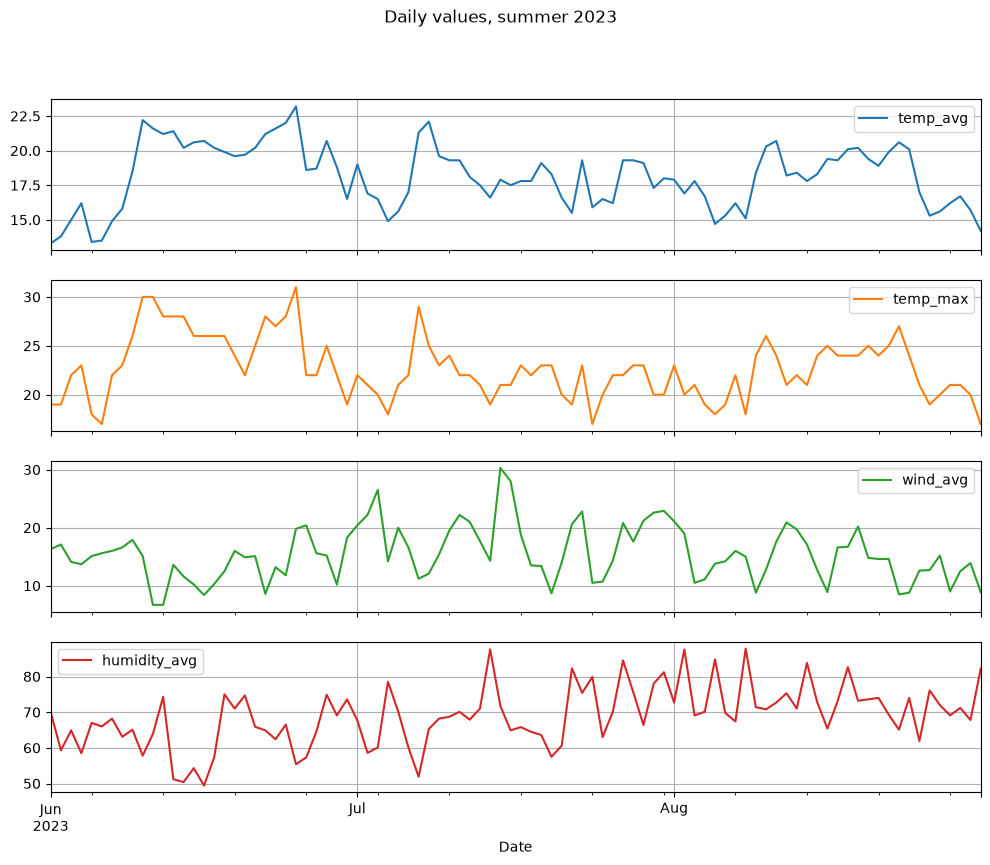

In [ ]:
cols = ["temp_avg", "temp_max", "wind_avg", "humidity_avg"]
summer[cols].plot(subplots=True, grid=True, figsize=(12, 9), title="Daily values, summer 2023")

**What the daily charts show:** Temperature was highest in late June, when the average and maximum temperatures peaked together, with another warm stretch just before mid-June. There was a cooler stretch from mid-July to early August before temperatures picked up again. Wind speed was lowest around mid-June and peaked in mid-July, with the windiest day above 30 km/h. Humidity was also lowest around mid-June and stayed high from mid-July into August.

##### Why a 14-day rolling average
A holiday lasts a stretch of days, not a single day, and the daily values jump up and down a lot. Looking for the best single days would not tell me when to book.

A **rolling average** takes each day together with the 13 days before it and averages them, which smooths out the noise and gives one figure for every possible 14-day period. I chose 14 days because it is a typical two-week holiday. It is a choice and could be changed.

The first 13 days of summer cannot have a full 14-day window, so they are dropped. That leaves 79 periods (92 − 14 + 1).

(79, 4)


array([<Axes: xlabel='Date'>, <Axes: xlabel='Date'>,
       <Axes: xlabel='Date'>, <Axes: xlabel='Date'>], dtype=object)

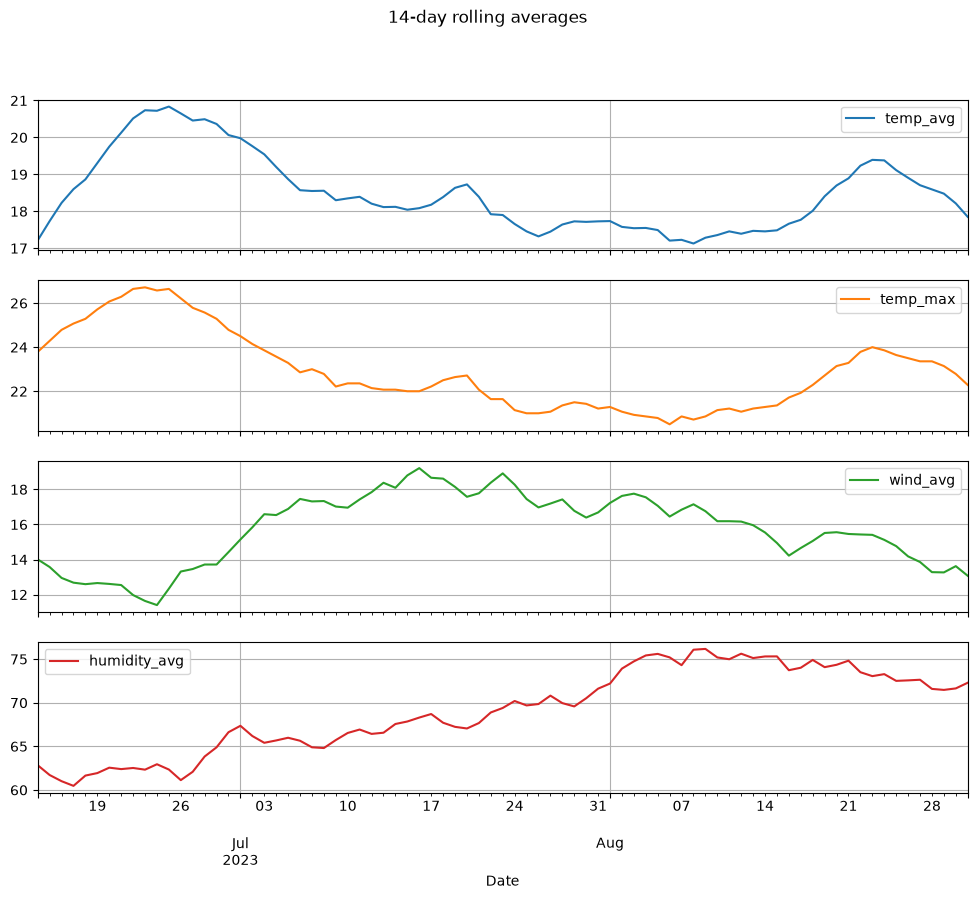

In [ ]:
WINDOW = 14   # days in one holiday period

rolling = summer[cols].rolling(WINDOW).mean().dropna()
rolling.columns = ["temp_avg", "temp_max", "wind_avg", "humidity_avg"]
print(rolling.shape)

rolling.plot(subplots=True, grid=True, figsize=(12, 9), title="14-day rolling averages")

### What counts as good holiday weather?
Because I cannot use rain, I define a good period with a simple rule:
1. **Calm:** the average wind speed is at or below the median of all periods.
2. **Warm:** among the calm periods, the highest average temperature is best.

I check humidity afterwards, as a comfort check on the winners. Each rolling value is labelled with the **last** day of its window, so I work out the start date as the end date minus 13 days.

The second choice has to be a separate period, since the neighbouring windows of the best one share almost all of their days. So I require the two chosen periods not to overlap.

In [ ]:
rolling["end"] = rolling.index
rolling["start"] = rolling["end"] - pd.Timedelta(days=WINDOW - 1)

calm = rolling["wind_avg"] <= rolling["wind_avg"].median()            # rule 1
ranked = rolling[calm].sort_values("temp_avg", ascending=False)       # rule 2

chosen = []
for _, row in ranked.iterrows():
    # keep a period only if it does not overlap any period already chosen
    if all(abs((row["end"] - c["end"]).days) >= WINDOW for c in chosen):
        chosen.append(row)
    if len(chosen) == 2:
        break

#picks = pd.DataFrame(chosen)[["start", "end", "temp_avg", "temp_max", "wind_avg", "humidity_avg"]].round(1)
#picks

# Create the DataFrame
picks = pd.DataFrame(chosen)[["start", "end", "temp_avg", "temp_max", "wind_avg", "humidity_avg"]]

# Define numeric columns to round
numeric_cols = ["temp_avg", "temp_max", "wind_avg", "humidity_avg"]
picks[numeric_cols] = picks[numeric_cols].round(1)
picks

,start,end,temp_avg,temp_max,wind_avg,humidity_avg
2023-06-25,2023-06-12,2023-06-25,20.8,26.6,12.3,62.3
2023-08-23,2023-08-10,2023-08-23,19.4,24.0,15.4,73.0


### Showing the two best periods
To check the result, I plot the summer temperature and show the chosen periods as extra lines on top of it.

<Axes: title={'center': 'The two best 14-day periods, summer 2023'}, xlabel='Date'>

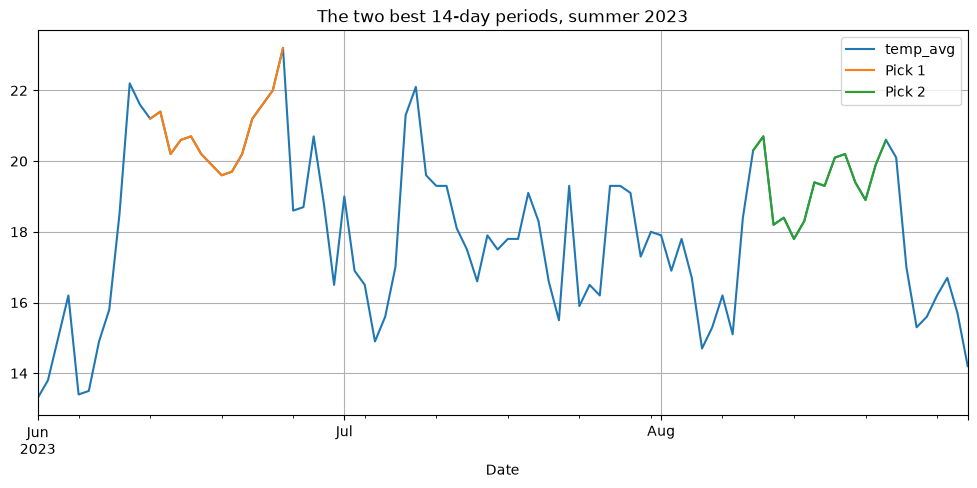

In [ ]:
marked = summer[["temp_avg"]].copy()
for i, (_, p) in enumerate(picks.iterrows(), start=1):
    in_period = (marked.index >= p["start"]) & (marked.index <= p["end"])
    marked[f"Pick {i}"] = marked["temp_avg"].where(in_period)   # NaN outside the period

marked.plot(grid=True, figsize=(12, 5), title="The two best 14-day periods, summer 2023")

### What I found
- **Best period 1:** 12 to 25 June 2023, with an average temperature of 20.8 °C, an average maximum of 26.6 °C, average wind of 12.3 km/h and average humidity of 62.3%.
- **Best period 2:** 10 to 23 August 2023, with an average temperature of 19.4 °C, an average maximum of 24.0 °C, average wind of 15.4 km/h and average humidity of 73.0%.
- **Compared with each other:** the June period is 1.4 °C warmer on average, 2.6 °C warmer at its maximum, calmer, and less humid.
- **Compared with the whole summer:** the typical 14-day period had an average temperature of 18.3 °C, wind of 16.2 km/h and humidity of 69.4%. The June period is 2.5 °C warmer, 3.9 km/h calmer and 7.1 percentage points less humid than that. The August period is only 1.1 °C warmer and 0.8 km/h calmer, and it is 3.6 points more humid.


### Recommendations
- **First choice: 12 to 25 June.** It is the warmest, calmest and least humid of the two, so it is the best choice if the weather is the only thing that matters.
- **Second choice: 10 to 23 August.**  It is only slightly better than a typical summer period on temperature and wind, and it is more humid than typical, so I would treat it as a fallback if June is not possible.

### Limitations
- The data is for **one year (2023)**, and a future summer may be different.
- **Precipitation was zero on every day**, so rain, a major factor for a holiday, is not in my analysis.
- My rule (calm first, then warm) is one reasonable choice. Another rule, such as capping the temperature to avoid very hot weeks, could give different dates.
- Humidity was used only as a comfort check after the periods were chosen, not as part of the ranking.

### Final conclusion
I wanted to find the two best periods for a summer holiday in London, using the 2023 Heathrow data. I used a 14-day rolling average of temperature, wind and humidity, kept the calmer half of the periods, and chose the warmest two that did not overlap. The best period was 12 to 25 June, and the second was 10 to 23 August. The main caveat is that rainfall was missing, so these dates should be checked against a rain record before booking.

---
# Part B: Transforming & Combining Data

### Provide `2-Transforming & Combining Data/1.ipynb` Tasks Solutions below (Execute them)

In [ ]:
import sys, pathlib
import pandas as pd
from scipy.stats import spearmanr
%matplotlib inline

_p = pathlib.Path.cwd()
while _p != _p.parent and not (_p / "db" / "dataraflow_db.py").exists():
    _p = _p.parent
sys.path.insert(0, str(_p))
from db.dataraflow_db import run_query

In [ ]:
from scipy.stats import spearmanr

In [ ]:
# Constants: column names used again and again, written once
GDP_USD = 'GDP (US$)'
GDP_GBP = 'GDP (£m)'
COUNTRY_NAME = 'Country name'

def usdToGBP(usd):
    return usd / 1.564768            # average 2013 dollar-to-pound rate used in the lesson

def roundToMillions(value):
    return round(value / 1000000)

def expandCountry(name):
    # Turn short names into the full names used in the other table
    full = {'UK': 'United Kingdom', 'USA': 'United States'}
    return full.get(name, name)      # leave other names unchanged

gdp = pd.DataFrame(columns=['Country', GDP_USD], data=[
    ['UK', 2678454886796.7], ['USA', 16768100000000.0], ['China', 9240270452047.0],
    ['Brazil', 2245673032353.8], ['South Africa', 366057913367.1]])

life = pd.DataFrame(columns=[COUNTRY_NAME, 'Life expectancy (years)'], data=[
    ['China', 75], ['Russia', 71], ['United States', 79], ['India', 66], ['United Kingdom', 81]])

gdp[COUNTRY_NAME] = gdp['Country'].apply(expandCountry)
gdp[GDP_GBP] = gdp[GDP_USD].apply(usdToGBP).apply(roundToMillions)
gdp = gdp[[COUNTRY_NAME, GDP_GBP]]

print(pd.merge(gdp, life, on=COUNTRY_NAME, how='left'))

     Country name  GDP (£m)  Life expectancy (years)
0  United Kingdom   1711727                     81.0
1   United States  10716029                     79.0
2           China   5905202                     75.0
3          Brazil   1435148                      NaN
4    South Africa    233937                      NaN


In [ ]:
table = [
  ['UK', 2678454886796.7],    # 1st row
  ['USA', 16768100000000.0],  # 2nd row
  ['China', 9240270452047.0], # and so on...
  ['Brazil', 2245673032353.8],
  ['South Africa', 366057913367.1]
]

headings =['country', 'GDP (US$)']
gdp = pd.DataFrame(columns=headings, data=table)
gdp

,country,GDP (US$)
0,UK,2.678455e+12
1,USA,1.676810e+13
2,China,9.240270e+12
3,Brazil,2.245673e+12
4,South Africa,3.660579e+11


In [ ]:
headings = ['country name', 'Life expectancy (years)']
table = [
    ['China', 75],
    ['Russia', 71],
    ['United States', 79],
    ['India', 66],
    ['United Kingdom', 81]
]
life = pd.DataFrame(columns=headings, data=table)

In [ ]:
def roundToMillions(value):
    return round(value / 1000000)

def usdToGBP(usd):
    return usd / 1.564768 #average rate during 2013

def expandCountry(name):
    if name == 'UK':
        return 'United Kingdom'
    elif name == 'USA':
        return 'United States'
    else:
        return name

gdp['country name'] = gdp['country'].apply(expandCountry)
gdp['GDP (£m)'] = gdp['GDP (US$)'].apply(usdToGBP).apply(roundToMillions)
gdp['GDP (US$)'] = gdp['GDP (US$)'].apply(roundToMillions).apply(usdToGBP).apply(round)
headings = ['country name', 'GDP (£m)']
gdp = gdp[headings]

In [ ]:
gdpVsLife = pd.merge(gdp, life, on='country name', how='inner')
gdpVsLife

,country name,GDP (£m),Life expectancy (years)
0,United Kingdom,1711727,81
1,United States,10716029,79
2,China,5905202,75


**TASK** 1.
 Create your population dataframe `'Country name', 'Life expectancy (years)'`.


In [ ]:
#population = pd.DataFrame('Country name', 'Life expectancy (years)')

population = pd.DataFrame({
    'country name': ['India', 'United Kingdom', 'japan', 'Brazil', 'United States'],
    'life expectancy (years)': [78, 94, 84, 23, 64]
})
population

,country name,life expectancy (years)
0,India,78
1,United Kingdom,94
2,japan,84
3,Brazil,23
4,United States,64


**TASK 2.**

Join your population dataframe previous task with gdpVsLife, in four different ways, and note the differences.

In [ ]:
popVsGDP = pd.merge(population, gdpVsLife, on='country name', how='left')
popVsGDP

,country name,life expectancy (years),GDP (£m),Life expectancy (years)
0,India,78,NaN,NaN
1,United Kingdom,94,1711727.0,81.0
2,japan,84,NaN,NaN
3,Brazil,23,NaN,NaN
4,United States,64,10716029.0,79.0


In [ ]:
popVsGDP = pd.merge(population, gdpVsLife, on='country name', how='inner')
popVsGDP

,country name,life expectancy (years),GDP (£m),Life expectancy (years)
0,United Kingdom,94,1711727,81
1,United States,64,10716029,79


In [ ]:
popVsGDP = pd.merge(population, gdpVsLife, on='country name', how='right')
popVsGDP

,country name,life expectancy (years),GDP (£m),Life expectancy (years)
0,United Kingdom,94.0,1711727,81
1,United States,64.0,10716029,79
2,China,NaN,5905202,75


In [ ]:
popVsGDP = pd.merge(population, gdpVsLife, on='country name', how='outer')
popVsGDP

,country name,life expectancy (years),GDP (£m),Life expectancy (years)
0,Brazil,23.0,NaN,NaN
1,China,NaN,5905202.0,75.0
2,India,78.0,NaN,NaN
3,United Kingdom,94.0,1711727.0,81.0
4,United States,64.0,10716029.0,79.0
5,japan,84.0,NaN,NaN


### Provide `2-Transforming & Combining Data/2.ipynb` Tasks Solutions below (Execute them)

In [ ]:
# Load Data from cohort database (schema week08). See "Data Access (SQL).md".
import sys, pathlib
_p = pathlib.Path.cwd()
while _p != _p.parent and not (_p / "db" / "dataraflow_db.py").exists():
    _p = _p.parent
sys.path.insert(0, str(_p))
from db.dataraflow_db import run_query

GDP_INDICATOR = 'NY.GDP.MKTP.CD'
gdpReset = run_query("SELECT * FROM week08.wb_gdp_2013")

LIFE_INDICATOR = 'SP.DYN.LE00.IN'
lifeReset = run_query("SELECT * FROM week08.wb_le_2013")

Tasks   1

Create a data frame with the World Bank's data on population, using the CSV file provided. This dataframe will be used in the remaining task.

In [ ]:

POP_INDICATOR = 'SP.POP.TOTL'
popReset = run_query("SELECT * FROM week08.wb_pop_2013")

In [ ]:
print(popReset.shape)
print(popReset.columns.tolist())
popReset.head(40)

(248, 3)
['country', 'year', 'SP.POP.TOTL']


,country,year,SP.POP.TOTL
0,Arab World,2013,3.770967e+08
1,Caribbean small states,2013,6.975819e+06
2,Central Europe and the Baltics,2013,1.037137e+08
3,East Asia & Pacific (all income levels),2013,2.248867e+09
4,East Asia & Pacific (developing only),2013,2.006073e+09
5,Euro area,2013,3.372839e+08
6,Europe & Central Asia (all income levels),2013,8.988371e+08
7,Europe & Central Asia (developing only),2013,2.624163e+08
8,European Union,2013,5.065580e+08
9,Fragile and conflict affected situations,2013,4.617132e+08


#### cleaning

In [ ]:
gdpCountries = gdpReset[34:]
lifeCountries = lifeReset[34:]
#gdpCountries.head()

#drop missing vallues
gdpData = gdpCountries.dropna()
lifeData = lifeCountries.dropna()
#gdpData.head()


#discard the year column
COUNTRY = 'country'
headings = [COUNTRY, GDP_INDICATOR]
gdpClean = gdpData[headings]
headings = [COUNTRY, LIFE_INDICATOR]
lifeClean= lifeData[headings]
lifeClean.head()

,country,SP.DYN.LE00.IN
34,Afghanistan,60.028268
35,Albania,77.537244
36,Algeria,74.568951
39,Angola,51.866171
40,Antigua and Barbuda,75.778659


**Task 2**

Clean the population dataframe you created in the previous task.

In [ ]:
popCountries = popReset[34:]
popCountries.shape

(214, 3)

In [ ]:
#drop missing row
popData = popCountries.dropna()

In [ ]:

COUNTRY = 'country'
headings = [COUNTRY, POP_INDICATOR]
popClean = popData[headings]
popClean.head()

,country,SP.POP.TOTL
34,Afghanistan,30682500.0
35,Albania,2897366.0
36,Algeria,38186135.0
37,American Samoa,55302.0
38,Andorra,75902.0


#### merging the dataframes before task 3


In [ ]:
#### mergind the dataframes before task 3
gdpVsLifeAll = pd.merge(gdpClean, lifeClean, on=COUNTRY, how='inner')
#gdpVsLifeAll.head()

#The dollars are converted to million pounds.
GDP = 'GDP (£m)'
column = gdpVsLifeAll[GDP_INDICATOR]
gdpVsLifeAll[GDP] = column.apply(usdToGBP).apply(roundToMillions)
#gdpVsLifeAll.head()


#The life expectancy is rounded, by applying the round() function.

LIFE = 'Life expectancy (years)'
gdpVsLifeAll[LIFE] = gdpVsLifeAll[LIFE_INDICATOR].apply(round)
#gdpVsLifeAll.head()

#The original GDP and life expectancy columns are dropped.
headings = [COUNTRY, GDP, LIFE]
gdpVsLifeClean = gdpVsLifeAll[headings]
gdpVsLifeClean.head()

,country,GDP (£m),Life expectancy (years)
0,Afghanistan,13075,60
1,Albania,8168,78
2,Algeria,134016,75
3,Angola,88420,52
4,Antigua and Barbuda,767,76


Task 3

Merge `gdpVsLifeClean` with the population dataframe obtained in the previous exercise. - Round the population value to the nearest million. - Remove the original population column.

In [ ]:
gdpVsLifeVsPop = pd.merge(gdpVsLifeClean, popClean, on='country', how='inner')
gdpVsLifeVsPop.head()

,country,GDP (£m),Life expectancy (years),SP.POP.TOTL
0,Afghanistan,13075,60,30682500.0
1,Albania,8168,78,2897366.0
2,Algeria,134016,75,38186135.0
3,Angola,88420,52,23448202.0
4,Antigua and Barbuda,767,76,89985.0


In [ ]:
POP = 'Population (millions)'
gdpVsLifeVsPop[POP] = gdpVsLifeVsPop[POP_INDICATOR].apply(roundToMillions)
gdpVsLifeVsPop.head()

,country,GDP (£m),Life expectancy (years),SP.POP.TOTL,Population (millions)
0,Afghanistan,13075,60,30682500.0,31
1,Albania,8168,78,2897366.0,3
2,Algeria,134016,75,38186135.0,38
3,Angola,88420,52,23448202.0,23
4,Antigua and Barbuda,767,76,89985.0,0


In [ ]:
headings = [COUNTRY, GDP, LIFE, POP]
gdpVsLifeVsPopClean = gdpVsLifeVsPop[headings]
gdpVsLifeVsPopClean.head()

,country,GDP (£m),Life expectancy (years),Population (millions)
0,Afghanistan,13075,60,31
1,Albania,8168,78,3
2,Algeria,134016,75,38
3,Angola,88420,52,23
4,Antigua and Barbuda,767,76,0


**Task 4**

Calculate the correlation between GDP and population.

In [ ]:
gdpColumn = gdpVsLifeVsPop[GDP]
popColumn = gdpVsLifeVsPop[POP]
(correlation, pValue) = spearmanr(gdpColumn, popColumn)
print('the correlation is ', correlation)
if pValue < 0.05:
    print('It is statistically significant')
else:
    print('its not statisticlly significant')

the correlation is  0.7056367228611176
It is statistically significant


**Task 5**

Swap the axes of the scatterplot, i.e. show the GDP in the y axis and the life expectancy in the x axis.

Display a scatterplot of the GDP and the population.

<Axes: xlabel='Life expectancy (years)', ylabel='GDP (£m)'>

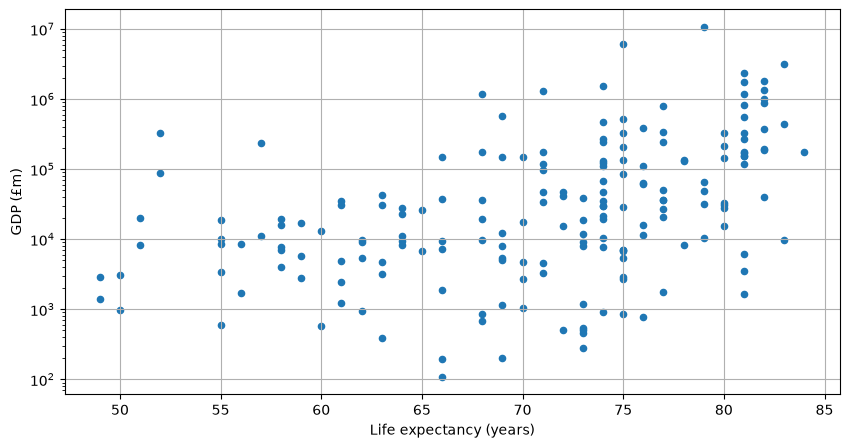

In [ ]:
gdpVsLifeClean.plot(x=LIFE, y=GDP, kind='scatter',logy=True, grid=True, figsize=(10,5))

<Axes: xlabel='GDP (£m)', ylabel='Population (millions)'>

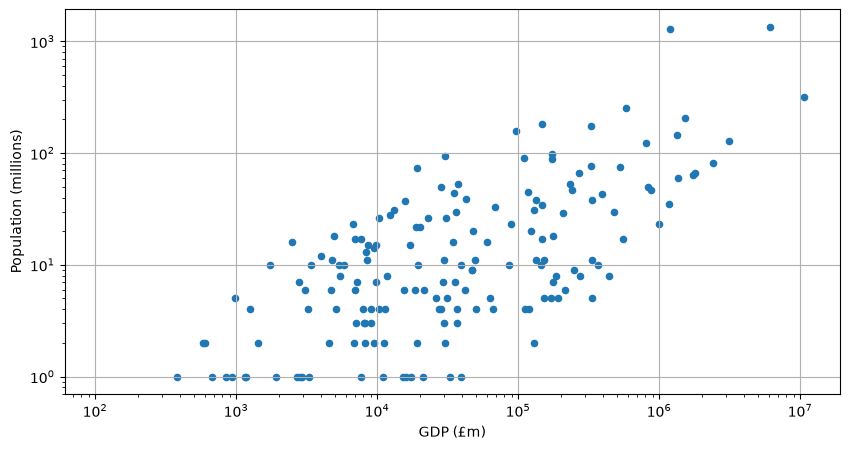

In [ ]:
gdpVsLifeVsPopClean.plot(x=GDP,  y=POP, kind='scatter',logx=True, logy=True, grid=True, figsize=(10,5))

In [ ]:
#top 10 by GDP vs top 10 by life expectancy
top_gdp  = gdpVsLifeVsPop.nlargest(10, GDP)
top_life = gdpVsLifeVsPop.nlargest(10, LIFE, keep='all')   # keep='all' keeps ties at the cut-off

overlap = set(top_gdp[COUNTRY]) & set(top_life[COUNTRY])
print(len(overlap), sorted(overlap))
print(len(top_life), "rows in the life list")

3 ['France', 'Italy', 'Japan']
12 rows in the life list


In [ ]:
top_gdp

,country,GDP (£m),Life expectancy (years),SP.POP.TOTL,Population (millions)
177,United States,10715999,79,3.164975e+08,316
35,China,6065182,75,1.357380e+09,1357
83,Japan,3143957,83,1.273386e+08,127
62,Germany,2393529,81,8.064560e+07,81
58,France,1795953,82,6.592550e+07,66
176,United Kingdom,1733354,81,6.410678e+07,64
23,Brazil,1528714,74,2.042594e+08,204
81,Italy,1363486,82,6.023395e+07,60
138,Russian Federation,1328647,71,1.435069e+08,144
75,India,1189826,68,1.279499e+09,1279


In [ ]:
top_life.head(10)

,country,GDP (£m),Life expectancy (years),SP.POP.TOTL,Population (millions)
72,"Hong Kong SAR, China",176220,84,7187500.0,7
74,Iceland,9827,83,323764.0,0
83,Japan,3143957,83,127338621.0,127
162,Switzerland,437713,83,8089346.0,8
7,Australia,999478,82,23125868.0,23
58,France,1795953,82,65925498.0,66
80,Israel,186870,82,8059500.0,8
81,Italy,1363486,82,60233948.0,60
99,Luxembourg,39491,82,543360.0,1
147,Singapore,193157,82,5399200.0,5


### Provide `2-Transforming & Combining Data/2.ipynb` Assignment Solutions below (Execute them)

**Assignment**

Extend the project
*Answer the following questions:*
- To what extent do the ten countries with the highest GDP coincide with the ten countries with the longest life expectancy?

- Which are the two countries in the right half of the plot (higher GDP) with life expectancy below 60 years?

- What factors could explain their lower life expectancy compared to countries with similar GDP? Hint: use the filtering techniques you learned in Week 2 to find the two countries.

- Redo the analysis using the countries’ GDP per capita (i.e. per inhabitant) instead of their total GDP. If you’ve done the workbook task, you already have a column with the population data.

Hint: write an expression involving the GDP and population columns, as you learned in Calculating over columns in previous modules. Think about the units in which you display GDP per capita.

Redo the analysis using the indicator suggested at the end of the project notebook.

In [ ]:
# ASSignmnets 1
# code ran above

The three countries that appear in both top-10 lists are France, Italy and Japan. All of the ten countries with the highest GDP have a life expectancy above 70 years except India at 68, so wealth and long life tend to go together at the top. However, the list of the longest-living countries also includes small economies such as Iceland, with a GDP of only 9,827 million pounds. The life expectancy list has more than 10 rows because several countries tie, as life expectancy is rounded to whole years. This suggests that total GDP is a crude measure: a small country can have a low total GDP and a long life expectancy.

In [ ]:
# ASSIGNMENT 2
#Which are the two countries in the right half of the plot (higher GDP) with life expectancy below 60 years?

low_life = gdpVsLifeVsPop[gdpVsLifeVsPop[LIFE] < 60].sort_values(GDP, ascending=False)
#print(low_life.head(8).to_string(index=False))

CUTOFF = 200000   # your choice from the table, with a reason
gdpVsLifeVsPop[(gdpVsLifeVsPop[GDP] > CUTOFF) & (gdpVsLifeVsPop[LIFE] < 60)]

,country,GDP (£m),Life expectancy (years),SP.POP.TOTL,Population (millions)
124,Nigeria,329100,52,172816517.0,173
152,South Africa,234056,57,53157490.0,53


Using a GDP cut-off of 200,000 (million pounds) and life expectancy below 60 years, the two countries are Nigeria and South Africa. They sit in the right half of the plot but well below the other countries with similar GDP.

In [ ]:
# Assignments 3
#What factors could explain their lower life expectancy compared to countries with similar GDP?
# Hint: use the filtering techniques you learned in Week 2 to find the two countries.


**What factors could explain their lower life expectancy compared to countries with similar GDP?**

Explanation: Total GDP says nothing about how wealth is shared or how many people it must cover. Other candidates are inequality, health-care access, conflict, disease burden (HIV, malaria) and population size.

(186, 4)
the correlation is  0.8502515138873855
It is statistically significant


<Axes: xlabel='GDP per capita (£)', ylabel='Life expectancy (years)'>

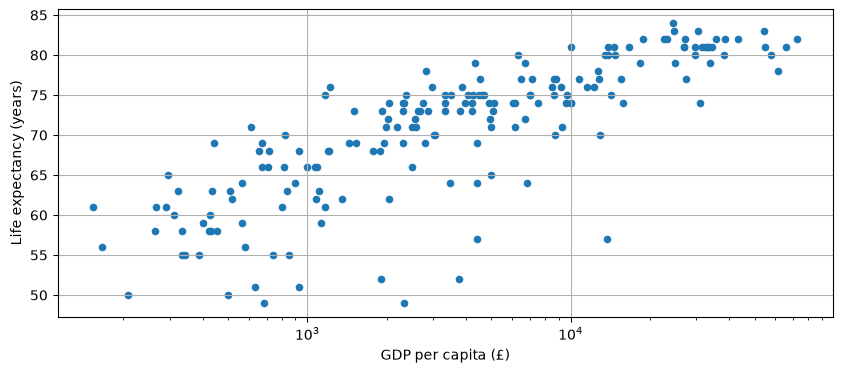

In [ ]:
# Assignemnt 4
#Redo the analysis using the countries’ GDP per capita (i.e. per inhabitant) instead of their total GDP.
#If you’ve done the workbook task, you already have a column with the population data

# Rebuild a table with GDP, life expectancy AND the exact (unrounded) population
POP_INDICATOR = 'SP.POP.TOTL'      # the population column in popClean
merged = pd.merge(gdpVsLifeClean, popClean, on=COUNTRY, how='inner')
print(merged.shape)                # same countries as gdpVsLifeVsPop

# GDP is in millions of pounds, so multiply by 1,000,000 before dividing by people
PCAP = 'GDP per capita (£)'
merged[PCAP] = (merged[GDP] * 1_000_000 / merged[POP_INDICATOR]).round(0)

# Correlation with life expectancy, in the same style as your other cells
pcapColumn = merged[PCAP]
lifeColumn = merged[LIFE]
(correlation, pValue) = spearmanr(pcapColumn, lifeColumn)
print('the correlation is ', correlation)
if pValue < 0.05:
    print('It is statistically significant')
else:
    print('its not statistically significant')

# Scatterplot with a log scale on the per-capita axis
merged.plot(x=PCAP, y=LIFE, kind='scatter', grid=True, logx=True, figsize=(10, 4))

In [ ]:
(corrTotal, pTotal) = spearmanr(gdpVsLifeVsPop[GDP], gdpVsLifeVsPop[LIFE])
print('total GDP vs life expectancy:', round(corrTotal, 3), '| p =', round(pTotal, 4))

total GDP vs life expectancy: 0.501 | p = 0.0


Using GDP per capita instead of total GDP, the Spearman correlation with life expectancy is 0.85, which is statistically significant. For total GDP it was 0.51, so dividing by population gives a much stronger relationship. This makes sense, because total GDP favours large countries, while GDP per capita compares the average wealth of people in each country. A strong correlation still does not prove that wealth causes longer lives.

5. analysis

In [ ]:
COUNTRY = 'Country Name'

In [ ]:
#LOAD and clean
PCAP_INDICATOR = 'GDP per capita, PPP (current international $)'   # my label for the column

raw = pd.read_csv("wb_gdp_pcap_ppp.csv", skiprows=4)
print(raw.shape)
print(raw.columns.tolist()[:6], "...", raw.columns.tolist()[-3:])
raw.head()

(266, 71)
['Country Name', 'Country Code', 'Indicator Name', 'Indicator Code', '1960', '1961'] ... ['2024', '2025', 'Unnamed: 70']


,Country Name,Country Code,Indicator Name,Indicator Code,1960,1961,1962,1963,1964,1965,...,2017,2018,2019,2020,2021,2022,2023,2024,2025,Unnamed: 70
0,Aruba,ABW,"GDP per capita, PPP (current international $)",NY.GDP.PCAP.PP.CD,NaN,NaN,NaN,NaN,NaN,NaN,...,37524.914920,39287.059713,38554.716783,28733.604511,35207.170909,41863.273996,47521.876547,51712.153136,NaN,NaN
1,Africa Eastern and Southern,AFE,"GDP per capita, PPP (current international $)",NY.GDP.PCAP.PP.CD,NaN,NaN,NaN,NaN,NaN,NaN,...,3843.028379,3727.710785,3804.533834,3707.033612,4022.277659,4359.591407,4496.744898,4635.125049,4840.265200,NaN
2,Afghanistan,AFG,"GDP per capita, PPP (current international $)",NY.GDP.PCAP.PP.CD,NaN,NaN,NaN,NaN,NaN,NaN,...,2335.795862,2432.276701,2583.485332,2561.981761,2144.166570,2122.659362,2203.537619,2236.199073,NaN,NaN
3,Africa Western and Central,AFW,"GDP per capita, PPP (current international $)",NY.GDP.PCAP.PP.CD,NaN,NaN,NaN,NaN,NaN,NaN,...,5035.762391,5188.368000,5491.687935,5423.594405,5702.134886,6232.323014,6538.812038,6840.333882,7184.664483,NaN
4,Angola,AGO,"GDP per capita, PPP (current international $)",NY.GDP.PCAP.PP.CD,NaN,NaN,NaN,NaN,NaN,NaN,...,8125.706394,8370.228758,8621.659308,7782.151534,8720.187687,9373.408309,9549.793139,9963.590209,10251.345706,NaN


In [ ]:
# Keep the country name and the 2013 values, then use the same column names as before
pcap = raw[['Country Name', '2013']].copy()
pcap.columns = [COUNTRY, PCAP_INDICATOR]
pcap = pcap.dropna()             # some countries have no 2013 value
print(pcap.shape)

(248, 2)


In [ ]:
print(gdpVsLifeVsPop.columns.tolist())

['country', 'GDP (£m)', 'Life expectancy (years)', 'SP.POP.TOTL', 'Population (millions)']


In [ ]:
gdpVsLifeVsPop = gdpVsLifeVsPop.rename(columns={"country": "Country Name"})

In [ ]:
pcap = pcap.rename(columns={"country": "Country Name"})

combine with life expectancy

In [ ]:
print(gdpVsLifeVsPop.columns.tolist())
print(gdpVsLifeVsPop.index.name)


['Country Name', 'GDP (£m)', 'Life expectancy (years)', 'SP.POP.TOTL', 'Population (millions)']
None


In [ ]:
print(pcap.columns.tolist())

['Country Name', 'GDP per capita, PPP (current international $)']


In [ ]:
lifeOnly = gdpVsLifeVsPop[[COUNTRY, LIFE]]      # your cleaned life expectancy by country
pcapVsLife = pd.merge(pcap, lifeOnly, on=COUNTRY, how='inner')
print(pcapVsLife.shape)

(177, 3)


In [ ]:
#see which countries didn’t match:
lost = set(lifeOnly[COUNTRY]) - set(pcap[COUNTRY])
print(len(lost), "countries lost:", sorted(lost))

9 countries lost: ['Cuba', 'Czech Republic', 'Faeroe Islands', 'Macedonia, FYR', 'Puerto Rico', 'Somalia', 'Swaziland', 'Turkey', 'Vietnam']


the correlation is  0.8519048281029835
It is statistically significant


<Axes: xlabel='GDP per capita, PPP (current international $)', ylabel='Life expectancy (years)'>

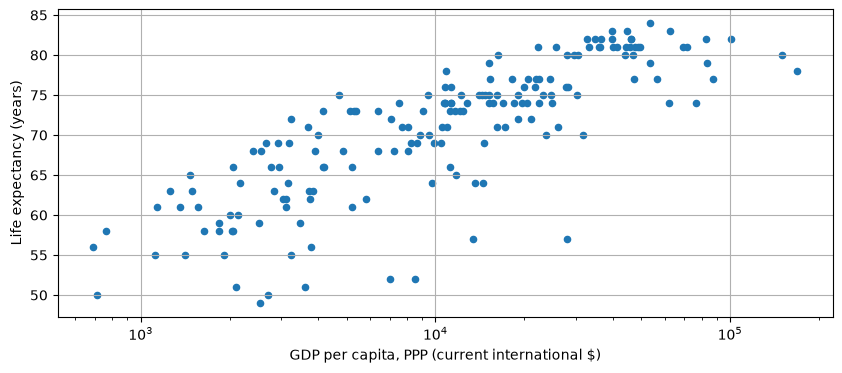

In [ ]:
(corr5, p5) = spearmanr(pcapVsLife[PCAP_INDICATOR], pcapVsLife[LIFE])
print('the correlation is ', corr5)
if p5 < 0.05:
    print('It is statistically significant')
else:
    print('its not statistically significant')

pcapVsLife.plot(x=PCAP_INDICATOR, y=LIFE, kind='scatter', grid=True, logx=True, figsize=(10, 4))

**Question 5. review** I downloaded GDP per capita, PPP (current international $) for 2013 from the World Bank and combined it with life expectancy for 177 countries; lost 9 countries, that did not match by name. The Spearman correlation is 0.8 and it is significant. This compares with 0.85 for GDP per capita in pounds (Question 4) and [your total-GDP value] for total GDP. Stronger, because this indicator adjusts for the cost of living in each country.

### Read and follow the below example analysis

## Project B: GDP and life expectancy

Richer countries can afford to invest more on healthcare, on work and road safety, and other measures that reduce mortality. On the other hand, richer countries may have less healthy lifestyles. Is there any relation between the wealth of a country and the life expectancy of its inhabitants?

The following analysis checks whether there is any correlation between the total gross domestic product (GDP) of a country in 2013 and the life expectancy of people born in that country in 2013.

## Getting the data

Two datasets of the World Bank are considered. One dataset, available at <http://data.worldbank.org/indicator/NY.GDP.MKTP.CD>, lists the GDP of the world's countries in current US dollars, for various years. The use of a common currency allows us to compare GDP values across countries. The other dataset, available at <http://data.worldbank.org/indicator/SP.DYN.LE00.IN>, lists the life expectancy of the world's countries. The datasets were downloaded as CSV files in March 2016.

In [ ]:
import warnings
warnings.simplefilter('ignore', FutureWarning)

import pandas as pd

# Load Data from cohort database (schema week08). See "Data Access (SQL).md".
import sys, pathlib
_p = pathlib.Path.cwd()
while _p != _p.parent and not (_p / "db" / "dataraflow_db.py").exists():
    _p = _p.parent
sys.path.insert(0, str(_p))
from db.dataraflow_db import run_query

YEAR = 2013
GDP_INDICATOR = 'NY.GDP.MKTP.CD'
gdpReset = run_query("SELECT * FROM week08.wb_gdp_2013")

LIFE_INDICATOR = 'SP.DYN.LE00.IN'
lifeReset = run_query("SELECT * FROM week08.wb_le_2013")
lifeReset.head()


,country,year,SP.DYN.LE00.IN
0,Arab World,2013,70.631305
1,Caribbean small states,2013,71.901964
2,Central Europe and the Baltics,2013,76.127583
3,East Asia & Pacific (all income levels),2013,74.604619
4,East Asia & Pacific (developing only),2013,73.657617


## Cleaning the data

Inspecting the data with `head()` and `tail()` shows that:

1. the first 34 rows are aggregated data, for the Arab World, the Caribbean small states, and other country groups used by the World Bank;
- GDP and life expectancy values are missing for some countries.

The data is therefore cleaned by:
1. removing the first 34 rows;
- removing rows with unavailable values.

In [ ]:
gdpCountries = gdpReset[34:].dropna()
lifeCountries = lifeReset[34:].dropna()

## Transforming the data

The World Bank reports GDP in US dollars and cents. To make the data easier to read, the GDP is converted to millions of British pounds (the author's local currency) with the following auxiliary functions, using the average 2013 dollar-to-pound conversion rate provided by <http://www.ukforex.co.uk/forex-tools/historical-rate-tools/yearly-average-rates>.

In [ ]:
def roundToMillions (value):
    return round(value / 1000000)

def usdToGBP (usd):
    return usd / 1.564768

GDP = 'GDP (£m)'
gdpCountries[GDP] = gdpCountries[GDP_INDICATOR].apply(usdToGBP).apply(roundToMillions)
gdpCountries.head()

,country,year,NY.GDP.MKTP.CD,GDP (£m)
34,Afghanistan,2013,2.045894e+10,13075
35,Albania,2013,1.278103e+10,8168
36,Algeria,2013,2.097035e+11,134016
38,Andorra,2013,3.249101e+09,2076
39,Angola,2013,1.383568e+11,88420


The unnecessary columns can be dropped.

In [ ]:
COUNTRY = 'country'
headings = [COUNTRY, GDP]
gdpClean = gdpCountries[headings]
gdpClean.head()

,country,GDP (£m)
34,Afghanistan,13075
35,Albania,8168
36,Algeria,134016
38,Andorra,2076
39,Angola,88420


The World Bank reports the life expectancy with several decimal places. After rounding, the original column is discarded.

In [ ]:
LIFE = 'Life expectancy (years)'
lifeCountries[LIFE] = lifeCountries[LIFE_INDICATOR].apply(round)
headings = [COUNTRY, LIFE]
lifeClean = lifeCountries[headings]
lifeClean.head()

,country,Life expectancy (years)
34,Afghanistan,60
35,Albania,78
36,Algeria,75
39,Angola,52
40,Antigua and Barbuda,76


## Combining the data

The tables are combined through an inner join on the common 'country' column.

In [ ]:
gdpVsLife = pd.merge(gdpClean, lifeClean, on=COUNTRY, how='inner')
gdpVsLife.head()

,country,GDP (£m),Life expectancy (years)
0,Afghanistan,13075,60
1,Albania,8168,78
2,Algeria,134016,75
3,Angola,88420,52
4,Antigua and Barbuda,767,76


## Calculating the correlation

To measure if the life expectancy and the GDP grow together, the Spearman rank correlation coefficient is used. It is a number from -1 (perfect inverse rank correlation: if one indicator increases, the other decreases) to 1 (perfect direct rank correlation: if one indicator increases, so does the other), with 0 meaning there is no rank correlation. A perfect correlation doesn't imply any cause-effect relation between the two indicators. A p-value below 0.05 means the correlation is statistically significant.

In [ ]:
from scipy.stats import spearmanr

gdpColumn = gdpVsLife[GDP]
lifeColumn = gdpVsLife[LIFE]
(correlation, pValue) = spearmanr(gdpColumn, lifeColumn)
print('The correlation is', correlation)
if pValue < 0.05:
    print('It is statistically significant.')
else:
    print('It is not statistically significant.')

The correlation is 0.5010232389671027
It is statistically significant.


The value shows a direct correlation, i.e. richer countries tend to have longer life expectancy, but it is not very strong.

## Showing the data

Measures of correlation can be misleading, so it is best to see the overall picture with a scatterplot. The GDP axis uses a logarithmic scale to better display the vast range of GDP values, from a few million to several billion (million of million) pounds.

<Axes: xlabel='GDP (£m)', ylabel='Life expectancy (years)'>

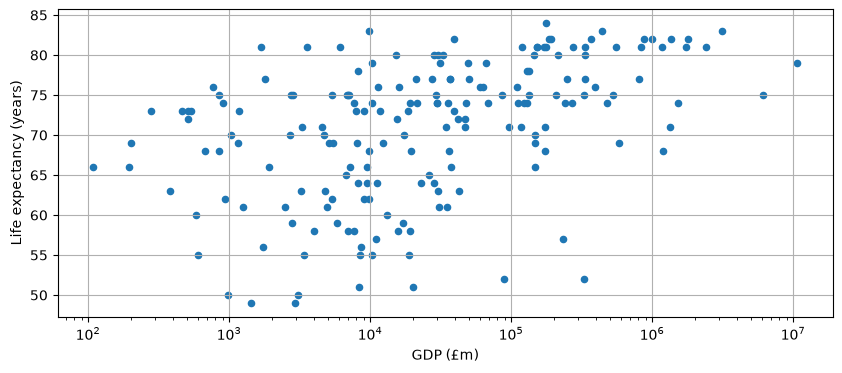

In [ ]:
%matplotlib inline
gdpVsLife.plot(x=GDP, y=LIFE, kind='scatter', grid=True, logx=True, figsize=(10, 4))

The plot shows there is no clear correlation: there are rich countries with low life expectancy, poor countries with high expectancy, and countries with around 10 thousand (10<sup>4</sup>) million pounds GDP have almost the full range of values, from below 50 to over 80 years. Towards the lower and higher end of GDP, the variation diminishes. Above 40 thousand million pounds of GDP (3rd tick mark to the right of 10<sup>4</sup>), most countries have an expectancy of 70 years or more, whilst below that threshold most countries' life expectancy is below 70 years.

Comparing the 10 poorest countries and the 10 countries with the lowest life expectancy shows that total GDP is a rather crude measure. The population size should be taken into account for a more precise definiton of what 'poor' and 'rich' means. Furthermore, looking at the countries below, droughts and internal conflicts may also play a role in life expectancy.

In [ ]:
# the 10 countries with lowest GDP
gdpVsLife.sort_values(GDP).head(10)

,country,GDP (£m),Life expectancy (years)
87,Kiribati,108,66
141,Sao Tome and Principe,195,66
111,"Micronesia, Fed. Sts.",202,69
168,Tonga,277,73
37,Comoros,383,63
157,St. Vincent and the Grenadines,461,73
140,Samoa,509,73
180,Vanuatu,512,72
65,Grenada,538,73
60,"Gambia, The",578,60


In [ ]:
# the 10 countries with lowest life expectancy
gdpVsLife.sort_values(LIFE).head(10)

,country,GDP (£m),Life expectancy (years)
95,Lesotho,1418,49
160,Swaziland,2916,49
146,Sierra Leone,3092,50
32,Central African Republic,983,50
41,Cote d'Ivoire,19998,51
33,Chad,8276,51
124,Nigeria,329100,52
3,Angola,88420,52
68,Guinea-Bissau,605,55
153,South Sudan,8473,55


## Conclusions

To sum up, there is no strong correlation between a country's wealth and the life expectancy of its inhabitants: there is often a wide variation of life expectancy for countries with similar GDP, countries with the lowest life expectancy are not the poorest countries, and countries with the highest expectancy are not the richest countries. Nevertheless there is some relationship, because the vast majority of countries with a life expectancy below 70 years is on the left half of the scatterplot.

Using the [NY.GDP.PCAP.PP.CD](http://data.worldbank.org/indicator/NY.GDP.PCAP.PP.CD) indicator, GDP per capita in current 'international dollars', would make for a better like-for-like comparison between countries, because it would take population and purchasing power into account. Using more specific data, like expediture on health, could also lead to a better analysis.

### Assessment - NOW IS YOUR TURN

**Create your own project**
Create a completely new project and choose another two of the
hundreds of World Bank indicators and see if there is any correlation between them. If
there is a choice of similar indicators, choose one that leads to meaningful
comparisons between countries.

Look at the results you obtained and take a few moments to assess how they differ.


## GOOD LUCK!

# Electricity Access and Internet Use

Using the internet depends on having power for devices, networks and data centres, so I expect countries where more people have electricity to also have more people online. But electricity may not be enough on its own, since people also need devices, coverage and money to pay for data.

The following analysis checks whether there is a correlation between the share of a country's population with **access to electricity** and the share of its population **using the internet** in 2023.

**My expectation before looking at the data:** a positive relationship, with some exceptions.

## Getting the data
Two World Bank indicators are used, both downloaded as CSV files:
- **Access to electricity (% of population)**, indicator code `EG.ELC.ACCS.ZS`
- **Individuals using the internet (% of population)**, indicator code `IT.NET.USER.ZS`

I chose the year **2023** for both. Both indicators are percentages, so countries of very different sizes can be compared directly.

In [ ]:
import pandas as pd
from scipy.stats import spearmanr
%matplotlib inline

YEAR = '2023'
COUNTRY = 'Country Name'
CODE = 'Country Code'


In [ ]:

IT_INDICATOR = 'IT.NET.USER.ZS'

internet_df = pd.read_csv("API_IT.NET.USER.ZS_DS2_en.csv", skipinitialspace=True, skiprows=4)
internet_df.head()

,Country Name,Country Code,Indicator Name,Indicator Code,1960,1961,1962,1963,1964,1965,...,2017,2018,2019,2020,2021,2022,2023,2024,2025,Unnamed: 70
0,Aruba,ABW,Individuals using the Internet (% of population),IT.NET.USER.ZS,NaN,NaN,NaN,NaN,NaN,NaN,...,97.17,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Africa Eastern and Southern,AFE,Individuals using the Internet (% of population),IT.NET.USER.ZS,NaN,NaN,NaN,NaN,NaN,NaN,...,17.30,19.600000,21.600000,23.5000,25.000000,26.800000,27.800000,28.800000,30.4,NaN
2,Afghanistan,AFG,Individuals using the Internet (% of population),IT.NET.USER.ZS,NaN,NaN,NaN,NaN,NaN,NaN,...,13.50,16.799999,17.600000,17.0485,16.514299,15.866300,15.928400,16.094999,NaN,NaN
3,Africa Western and Central,AFW,Individuals using the Internet (% of population),IT.NET.USER.ZS,NaN,NaN,NaN,NaN,NaN,NaN,...,23.80,25.700000,28.500000,31.5000,34.700000,37.500000,38.500000,40.000000,42.4,NaN
4,Angola,AGO,Individuals using the Internet (% of population),IT.NET.USER.ZS,NaN,NaN,NaN,NaN,NaN,NaN,...,26.00,29.000000,32.129398,33.3209,34.556499,35.838001,37.885899,40.704800,NaN,NaN


In [ ]:
ELEC_INDICATOR = 'EG.ELC.ACCS.ZS'

electricity_df = pd.read_csv("API_EG.ELC.ACCS.ZS_DS2_en.csv", skipinitialspace=True, skiprows=4)
electricity_df.head()

,Country Name,Country Code,Indicator Name,Indicator Code,1960,1961,1962,1963,1964,1965,...,2017,2018,2019,2020,2021,2022,2023,2024,2025,Unnamed: 70
0,Aruba,ABW,Access to electricity (% of population),EG.ELC.ACCS.ZS,NaN,NaN,NaN,NaN,NaN,NaN,...,100.000000,100.000000,100.000000,100.000000,100.000000,99.900000,100.000000,100.000000,NaN,NaN
1,Africa Eastern and Southern,AFE,Access to electricity (% of population),EG.ELC.ACCS.ZS,NaN,NaN,NaN,NaN,NaN,NaN,...,40.223744,43.035073,44.390861,46.282371,48.127211,48.742043,50.667516,52.598171,NaN,NaN
2,Afghanistan,AFG,Access to electricity (% of population),EG.ELC.ACCS.ZS,NaN,NaN,NaN,NaN,NaN,NaN,...,97.700000,93.400000,97.700000,97.700000,97.700000,85.300000,85.300000,87.800000,NaN,NaN
3,Africa Western and Central,AFW,Access to electricity (% of population),EG.ELC.ACCS.ZS,NaN,NaN,NaN,NaN,NaN,NaN,...,48.902228,51.338199,51.289374,51.851866,54.366012,55.585594,57.064737,58.822166,NaN,NaN
4,Angola,AGO,Access to electricity (% of population),EG.ELC.ACCS.ZS,NaN,NaN,NaN,NaN,NaN,NaN,...,42.900000,45.300000,45.600000,47.000000,48.200000,48.500000,51.100000,55.500000,NaN,NaN


In [ ]:
print("Electricity dataset")
print(electricity_df.shape)
print(electricity_df.columns.tolist())
display(electricity_df.head())

print("=====================+=========================================================================")
print("Internet dataset")
print(internet_df.shape)
print(internet_df.columns.tolist())
display(internet_df.head())

Electricity dataset
(266, 71)
['Country Name', 'Country Code', 'Indicator Name', 'Indicator Code', '1960', '1961', '1962', '1963', '1964', '1965', '1966', '1967', '1968', '1969', '1970', '1971', '1972', '1973', '1974', '1975', '1976', '1977', '1978', '1979', '1980', '1981', '1982', '1983', '1984', '1985', '1986', '1987', '1988', '1989', '1990', '1991', '1992', '1993', '1994', '1995', '1996', '1997', '1998', '1999', '2000', '2001', '2002', '2003', '2004', '2005', '2006', '2007', '2008', '2009', '2010', '2011', '2012', '2013', '2014', '2015', '2016', '2017', '2018', '2019', '2020', '2021', '2022', '2023', '2024', '2025', 'Unnamed: 70']


,Country Name,Country Code,Indicator Name,Indicator Code,1960,1961,1962,1963,1964,1965,...,2017,2018,2019,2020,2021,2022,2023,2024,2025,Unnamed: 70
0,Aruba,ABW,Access to electricity (% of population),EG.ELC.ACCS.ZS,NaN,NaN,NaN,NaN,NaN,NaN,...,100.000000,100.000000,100.000000,100.000000,100.000000,99.900000,100.000000,100.000000,NaN,NaN
1,Africa Eastern and Southern,AFE,Access to electricity (% of population),EG.ELC.ACCS.ZS,NaN,NaN,NaN,NaN,NaN,NaN,...,40.223744,43.035073,44.390861,46.282371,48.127211,48.742043,50.667516,52.598171,NaN,NaN
2,Afghanistan,AFG,Access to electricity (% of population),EG.ELC.ACCS.ZS,NaN,NaN,NaN,NaN,NaN,NaN,...,97.700000,93.400000,97.700000,97.700000,97.700000,85.300000,85.300000,87.800000,NaN,NaN
3,Africa Western and Central,AFW,Access to electricity (% of population),EG.ELC.ACCS.ZS,NaN,NaN,NaN,NaN,NaN,NaN,...,48.902228,51.338199,51.289374,51.851866,54.366012,55.585594,57.064737,58.822166,NaN,NaN
4,Angola,AGO,Access to electricity (% of population),EG.ELC.ACCS.ZS,NaN,NaN,NaN,NaN,NaN,NaN,...,42.900000,45.300000,45.600000,47.000000,48.200000,48.500000,51.100000,55.500000,NaN,NaN


=====================+=========================================================================
Internet dataset
(266, 71)
['Country Name', 'Country Code', 'Indicator Name', 'Indicator Code', '1960', '1961', '1962', '1963', '1964', '1965', '1966', '1967', '1968', '1969', '1970', '1971', '1972', '1973', '1974', '1975', '1976', '1977', '1978', '1979', '1980', '1981', '1982', '1983', '1984', '1985', '1986', '1987', '1988', '1989', '1990', '1991', '1992', '1993', '1994', '1995', '1996', '1997', '1998', '1999', '2000', '2001', '2002', '2003', '2004', '2005', '2006', '2007', '2008', '2009', '2010', '2011', '2012', '2013', '2014', '2015', '2016', '2017', '2018', '2019', '2020', '2021', '2022', '2023', '2024', '2025', 'Unnamed: 70']


,Country Name,Country Code,Indicator Name,Indicator Code,1960,1961,1962,1963,1964,1965,...,2017,2018,2019,2020,2021,2022,2023,2024,2025,Unnamed: 70
0,Aruba,ABW,Individuals using the Internet (% of population),IT.NET.USER.ZS,NaN,NaN,NaN,NaN,NaN,NaN,...,97.17,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Africa Eastern and Southern,AFE,Individuals using the Internet (% of population),IT.NET.USER.ZS,NaN,NaN,NaN,NaN,NaN,NaN,...,17.30,19.600000,21.600000,23.5000,25.000000,26.800000,27.800000,28.800000,30.4,NaN
2,Afghanistan,AFG,Individuals using the Internet (% of population),IT.NET.USER.ZS,NaN,NaN,NaN,NaN,NaN,NaN,...,13.50,16.799999,17.600000,17.0485,16.514299,15.866300,15.928400,16.094999,NaN,NaN
3,Africa Western and Central,AFW,Individuals using the Internet (% of population),IT.NET.USER.ZS,NaN,NaN,NaN,NaN,NaN,NaN,...,23.80,25.700000,28.500000,31.5000,34.700000,37.500000,38.500000,40.000000,42.4,NaN
4,Angola,AGO,Individuals using the Internet (% of population),IT.NET.USER.ZS,NaN,NaN,NaN,NaN,NaN,NaN,...,26.00,29.000000,32.129398,33.3209,34.556499,35.838001,37.885899,40.704800,NaN,NaN


Inspecting the data quality

In [ ]:


# Check missing values in recent years
years = ["2019", "2020", "2021", "2022", "2023", "2024", "2025"]

print("Electricity missing values:")
print(electricity_df[years].isna().sum())

print("\nInternet missing values:")
print(internet_df[years].isna().sum())


# Check the extra column
print("\nElectricity extra column:")
print(electricity_df["Unnamed: 70"].isna().sum(), "missing values out of",
      len(electricity_df))

print("\nInternet extra column:")
print(internet_df["Unnamed: 70"].isna().sum(), "missing values out of",
      len(internet_df))

Electricity missing values:
2019      3
2020      3
2021      3
2022      3
2023      3
2024      3
2025    266
dtype: int64

Internet missing values:
2019     45
2020     50
2021     54
2022     52
2023     53
2024     52
2025    224
dtype: int64

Electricity extra column:
266 missing values out of 266

Internet extra column:
266 missing values out of 266


: Clean and select the 2023 data

In [ ]:
# Which rows are real countries? Groups have an empty Region in the metadata file
meta = pd.read_csv("country_metadata.csv")
print(meta.columns.tolist())

countryCodes = meta.loc[meta['Region'].notna(), CODE]
print(len(countryCodes), "countries")                                   # expect roughly 200 to 220
print(meta[meta['Region'].isna()][CODE].head(10).tolist())              # these should be groups

# Missing values in 2023 before cleaning
print("electricity missing:", electricity_df[YEAR].isna().sum(), "| internet missing:", internet_df[YEAR].isna().sum())

['Country Code', 'Region', 'IncomeGroup', 'SpecialNotes', 'TableName', 'Unnamed: 5']
217 countries
['AFE', 'AFW', 'ARB', 'CEB', 'CSS', 'EAP', 'EAR', 'EAS', 'ECA', 'ECS']
electricity missing: 3 | internet missing: 53


In [ ]:
#a check to ensure the metadata appears in the data files too
print(electricity_df[CODE].isin(countryCodes).sum())    # expect 217
print(internet_df[CODE].isin(countryCodes).sum())       # expect 217

217
217


In [ ]:
# Keep only countries, keep the name, code and 2023 value, then drop missing values
ELEC = 'Electricity access (%)'
NET = 'Internet use (%)'

elecClean = electricity_df[electricity_df[CODE].isin(countryCodes)][[COUNTRY, CODE, YEAR]].dropna()
elecClean = elecClean.rename(columns={YEAR: ELEC})

netClean = internet_df[internet_df[CODE].isin(countryCodes)][[CODE, YEAR]].dropna()
netClean = netClean.rename(columns={YEAR: NET})

print(elecClean.shape, netClean.shape)
elecClean.head()

(215, 3) (181, 2)


,Country Name,Country Code,Electricity access (%)
0,Aruba,ABW,100.0
2,Afghanistan,AFG,85.3
4,Angola,AGO,51.1
5,Albania,ALB,100.0
6,Andorra,AND,100.0


## Transforming the data
The World Bank reports the percentages with many decimal places. Rounding them to one decimal place makes the table easier to read without changing the analysis.

In [ ]:
elecClean[ELEC] = elecClean[ELEC].round(1)
netClean[NET] = netClean[NET].round(1)
elecClean.head()

,Country Name,Country Code,Electricity access (%)
0,Aruba,ABW,100.0
2,Afghanistan,AFG,85.3
4,Angola,AGO,51.1
5,Albania,ALB,100.0
6,Andorra,AND,100.0


## Combining the data
The two tables are combined through an **inner join on the country code**. I use the code and not the name, because names can be spelled differently in different tables, while the three-letter codes are the same. An inner join keeps only the countries that have a value in both tables, so any country missing from either one is lost. I check how many.

In [ ]:
elecVsNet = pd.merge(elecClean, netClean, on=CODE, how='inner')
print(elecVsNet.shape)

# Which countries were lost, and why? (my own check for lost rows)
lostNoNet = set(elecClean[CODE]) - set(netClean[CODE])
lostNoElec = set(netClean[CODE]) - set(elecClean[CODE])
print("had electricity but no internet value:", len(lostNoNet))
print("had internet but no electricity value:", len(lostNoElec))

# Sanity check: both are percentages, so every value should be between 0 and 100
elecVsNet[[ELEC, NET]].describe()

(181, 4)
had electricity but no internet value: 34
had internet but no electricity value: 0


,Electricity access (%),Internet use (%)
count,181.000000,181.000000
mean,87.811050,71.695580
std,22.829036,25.338061
min,11.600000,7.200000
25%,88.300000,59.200000
50%,100.000000,81.700000
75%,100.000000,91.000000
max,100.000000,100.000000


In [ ]:
print((elecVsNet[ELEC] == 100).sum(), "countries at 100.0")
print((elecVsNet[ELEC] >= 99).sum(), "countries at 99 or above")

104 countries at 100.0
116 countries at 99 or above


In [ ]:
lost = elecClean[~elecClean[CODE].isin(netClean[CODE])]
print(lost[COUNTRY].tolist())

['Aruba', 'Bermuda', 'Botswana', 'Channel Islands', 'Curacao', 'Cayman Islands', 'Eritrea', 'Faroe Islands', 'Gibraltar', 'Greenland', 'Guam', 'Isle of Man', 'St. Martin (French part)', 'Myanmar', 'Northern Mariana Islands', 'New Caledonia', 'Pakistan', 'Puerto Rico (US)', "Korea, Dem. People's Rep.", 'French Polynesia', 'Sudan', 'South Sudan', 'Sint Maarten (Dutch part)', 'Syrian Arab Republic', 'Turks and Caicos Islands', 'Turkmenistan', 'Timor-Leste', 'Tunisia', 'Tuvalu', 'British Virgin Islands', 'Virgin Islands (U.S.)', 'Vanuatu', 'Samoa', 'Yemen, Rep.']


**What the combined data looks like:** 181 countries have both values for 2023. 36 of the 217 countries were dropped: 2 have no electricity figure and 34 more have electricity but no internet figure. Electricity access ranges from 11.6% to 100%, with a median of 100%, so most countries have almost full access. Internet use ranges from 7.2% to 100%, with a median of 81.7%, so it is much more spread out. 104 countries had a 100% internet access, and while the last cell shows that  lost countries whuch are mostly small island states or states with severe humanitarian crises and either had low aceess, or no access at all or data not being available.

## Calculating the correlation
To measure whether the two indicators grow together, I use the **Spearman rank correlation coefficient**. It goes from -1 (perfect inverse rank relationship) to 1 (perfect direct rank relationship), and 0 means no rank relationship. I use Spearman rather than a plain correlation because many countries are close to 100% electricity access, so the values bunch up at the top, and rank-based measures cope with that better.

A p-value below 0.05 means the correlation is statistically significant. A correlation, even a perfect one, does **not** show that one indicator causes the other.

In [ ]:
elecColumn = elecVsNet[ELEC]
netColumn = elecVsNet[NET]
(correlation, pValue) = spearmanr(elecColumn, netColumn)
print('The correlation is', correlation)
if pValue < 0.05:
    print('It is statistically significant.')
else:
    print('It is not statistically significant.')

The correlation is 0.8083005323381982
It is statistically significant.


**What the correlation shows:** the Spearman correlation is 0.81 and it is statistically significant, so there is a strong direct relationship between electricity access and internet use: countries where more people have electricity tend to have more people online. This is what I expected.

## Showing the data
A correlation number can be misleading, so I draw a scatterplot. Each country is a dot. Both indicators are percentages from 0 to 100, so no logarithmic scale is needed. I expect the dots to bunch up on the right, because many countries have almost full electricity access.

<Axes: title={'center': 'Internet use vs electricity access, 2023'}, xlabel='Electricity access (%)', ylabel='Internet use (%)'>

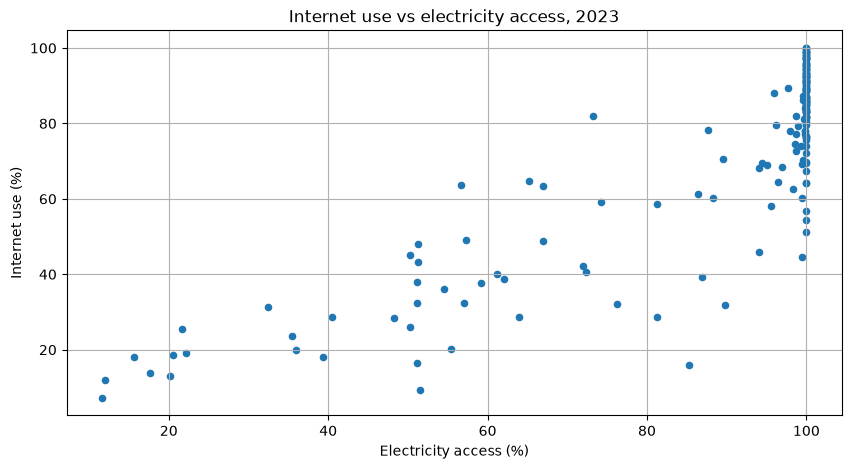

In [ ]:
elecVsNet.plot(x=ELEC, y=NET, kind='scatter', grid=True, figsize=(10, 5),
               title='Internet use vs electricity access, 2023')

In [ ]:
# Countries with full electricity: how spread out is internet use?
full = elecVsNet[elecVsNet[ELEC] == 100]
print(len(full), "countries at 100%")
print(full[NET].describe().round(1))

# Countries below full electricity: is the relationship stronger or weaker there?
rest = elecVsNet[elecVsNet[ELEC] < 100]
(c2, p2) = spearmanr(rest[ELEC], rest[NET])
print(len(rest), "countries below 100% | correlation:", round(c2, 3), "| p =", round(p2, 4))

104 countries at 100%
count    104.0
mean      87.5
std       10.0
min       51.2
25%       83.2
50%       89.4
75%       94.5
max      100.0
Name: Internet use (%), dtype: float64
77 countries below 100% | correlation: 0.836 | p = 0.0


In [ ]:
# Lowest and highest internet use
print(elecVsNet.sort_values(NET).head(10)[[COUNTRY, ELEC, NET]].to_string(index=False))
print(elecVsNet.sort_values(NET).tail(10)[[COUNTRY, ELEC, NET]].to_string(index=False))

# High electricity but low internet use (a threshold that matches what you saw on the chart)
mismatch = elecVsNet[(elecVsNet[ELEC] > 80) & (elecVsNet[NET] < 40)]
print(len(mismatch), "countries")
print(mismatch.sort_values(NET)[[COUNTRY, ELEC, NET]].to_string(index=False))

            Country Name  Electricity access (%)  Internet use (%)
                 Burundi                    11.6               7.2
                  Uganda                    51.5               9.3
                    Chad                    12.0              12.0
                   Niger                    20.1              13.0
Central African Republic                    17.6              13.8
             Afghanistan                    85.3              15.9
                  Zambia                    51.1              16.5
                  Malawi                    15.6              18.0
              Madagascar                    39.4              18.2
        Papua New Guinea                    20.5              18.6
        Country Name  Electricity access (%)  Internet use (%)
               Qatar                   100.0              98.2
             Denmark                   100.0              98.8
              Monaco                   100.0              98.9
   Brunei D

**What the chart shows:** the overall trend slopes upwards, so as electricity access falls, internet use falls too. Many countries bunch up at 100% electricity access (104 of 181, and 116 at 99% or above), and these countries have internet use anywhere from about 60% to 100%, so electricity access does not explain the differences among them. A few countries stand out: about four have more than 80% electricity access but less than 40% internet use, and one of them is below 20%.

**Does the block at 100% distort the result?** Over half the countries share the same electricity value, so I checked the correlation among only the 77 countries below 100%. It is 0.84 (p < 0.05), slightly higher than the overall 0.81. So the strong correlation is not just produced by the block at 100%: it holds among countries without full electricity access too.

## Conclusions
To sum up, there is a strong direct relationship between electricity access and internet use in 2023: the Spearman correlation is 0.81 and it is statistically significant. It is still strong (0.84) among the 77 countries without full electricity access, so the result does not come only from the many countries at 100%. However, electricity access does not explain everything: among the 104 countries with full access, internet use still ranges from 51.2% to 100%, and a few countries, such as Afghanistan and the Solomon Islands, have high electricity access but low internet use. This does not show that electricity access **causes** internet use: income, infrastructure and the cost of devices and data could affect both.

**Limitations**
- Only one year (2023) is used.
- 36 of the 217 countries had to be left out, because 2 have no electricity figure and 34 more have no internet figure. They may differ systematically from the countries kept, so the result may not apply to them.
- More than half of the countries have the same electricity value (100%), so the correlation says little about differences among them.
- A correlation is not a cause.

<!-- practice:start -->
---
## 🔁 SQL Practice

This week you cleaned messy weather data and combined World Bank tables in pandas. Now do the same jobs **in SQL**, straight from the raw tables: real analysts clean and combine data in the database before it ever reaches pandas.

**How it works**
1. Run the **practice setup** cell first (and again after restarting the kernel). It connects with your **read-only** account.
2. **SQL tasks:** write your query between the triple quotes and run the cell. `p.sql(...)` shows your result and
   says ✅ or ❌, and whether the **shape** (rows × columns) is right. Match the column order, sort order and rounding
   asked for (column *names* aren't checked).
3. Run `p.score()` at the end to see your practice score.

Refresh your memory with `Week-6 (Numpy & Pandas-1)/4-Intermediate SQL/Intermediate SQL.ipynb`.

In [ ]:
# --- practice setup: run this cell first (don't edit it) ---
import sys, pathlib
_p = pathlib.Path.cwd()
while _p != _p.parent and not (_p / "db" / "dataraflow_db.py").exists():
    _p = _p.parent
sys.path.insert(0, str(_p))
from db.practice import Practice, q

EXPECTED = {
 "s01": [
  [
   1,
   1
  ],
  "1ba5edf59854386be920ac9fd3e4a2af3bb6369bf2a1aef78dcdf908c96d70a9"
 ],
 "s02": [
  [
   5,
   3
  ],
  "19042d389224a7f56403ad9636ed581989f6639acadf45b15461f55cd6258da7"
 ],
 "s03": [
  [
   10,
   3
  ],
  "e3e296058facb3595b46ac98fb75d445a82240fc775f3188d029eabc5a362ddb"
 ],
 "s04": [
  [
   1,
   1
  ],
  "ba4a24ee999caa9e01607eb78856b7212bcce521b0f6fd42d8aa90541c10382d"
 ],
 "s05": [
  [
   1,
   2
  ],
  "8153d8bbbc1b43b88ce7e4ea0c99a4ac07f4b19e0f62a9a1e04df3271f2ad3df"
 ]
}   # fingerprints only: the answers are not stored here
TITLES = {
 "s01": "Cleaning a messy column",
 "s02": "Dates: a date range",
 "s03": "Combining tables (JOIN)",
 "s04": "What gets lost in a join?",
 "s05": "Window: the driest summer week"
}
p = Practice(EXPECTED, TITLES)
print(f"Practice ready: {len(TITLES)} tasks. Connected as:", q("SELECT CURRENT_USER AS u").u[0])

Practice ready: 5 tasks. Connected as: intern_readonly


### SQL Task 1 · Cleaning a messy column

`week07.london_2014` is the **raw** export: the last column is literally named `WindDirDegrees<br />` and every
value ends in `<br />` (e.g. `'186<br />'`). Clean it **in SQL**: remove the `<br />`, convert to an integer, and
count the days when the wind direction was **greater than 350 degrees**.

**Return:** one row, one column (`days_over_350`).
💡 `REPLACE(...)`, `TRY_CAST(... AS int)`, and bracket-quote the odd column name: `[WindDirDegrees<br />]`.

In [ ]:
SQL_01 = """
SELECT
    COUNT(*) AS days_over_350
FROM week07.london_2014
WHERE TRY_CAST(
    REPLACE([WindDirDegrees<br />], '<br />', '')
    AS INT
) > 350;
"""
p.sql("s01", SQL_01)

,days_over_350
0,5


✅ s01: correct!


,days_over_350
0,5


### SQL Task 2 · Dates: a date range

`GMT` is stored as **text** like `'2014-1-1'`. Convert it to a real date and return London's weather for
**8–12 December 2014** (inclusive).

**Return:** `day` (a date), `Max TemperatureC`, `Min TemperatureC`, sorted by `day`.
💡 `TRY_CONVERT(date, GMT)` and `BETWEEN`.

In [ ]:
SQL_02 = """
SELECT TRY_CONVERT(date, GMT) AS day,
       [Max TemperatureC],
       [Min TemperatureC]
FROM week07.london_2014
WHERE TRY_CONVERT(date, GMT) BETWEEN '2014-12-08' AND '2014-12-12'
ORDER BY day
"""
p.sql("s02", SQL_02)

,day,Max TemperatureC,Min TemperatureC
0,2014-12-08,7,1
1,2014-12-09,12,-1
2,2014-12-10,9,6
3,2014-12-11,10,5
4,2014-12-12,9,2


✅ s02: correct!


,day,Max TemperatureC,Min TemperatureC
0,2014-12-08,7,1
1,2014-12-09,12,-1
2,2014-12-10,9,6
3,2014-12-11,10,5
4,2014-12-12,9,2


### SQL Task 3 · Combining tables (JOIN)

Join `week08.wb_gdp_2013` and `week08.wb_le_2013` on `country`. Among entries with GDP **below 10 billion USD**
and a known life expectancy, return the **10 with the highest life expectancy**.

**Return:** `country`, `gdp_bn_usd` (GDP in billions, **rounded to 2 dp**), `life_expectancy` (**rounded to 1 dp**),
sorted by life expectancy (highest first), then `country` (A→Z) for ties.

In [ ]:
SQL_03 = """
SELECT TOP 10
    g.country,
    ROUND(g.[NY.GDP.MKTP.CD] / 1000000000.0, 2)
        AS gdp_bn_usd,
    ROUND(l.[SP.DYN.LE00.IN], 1)
        AS life_expectancy
FROM week08.wb_gdp_2013 AS g
INNER JOIN week08.wb_le_2013 AS l
    ON g.country = l.country
WHERE g.[NY.GDP.MKTP.CD] < 10000000000
  AND l.[SP.DYN.LE00.IN] IS NOT NULL
ORDER BY
    l.[SP.DYN.LE00.IN] DESC,
    g.country ASC;
"""
p.sql("s03", SQL_03)

,country,gdp_bn_usd,life_expectancy
0,Faeroe Islands,2.61,81.3
1,Malta,9.64,80.7
2,Bermuda,5.57,80.6
3,Maldives,2.79,76.6
4,Antigua and Barbuda,1.20,75.8
5,Barbados,4.28,75.3
6,"Bahamas, The",8.43,75.1
7,St. Lucia,1.33,74.9
8,Montenegro,4.46,74.8
9,Seychelles,1.41,74.2


✅ s03: correct!


,country,gdp_bn_usd,life_expectancy
0,Faeroe Islands,2.61,81.3
1,Malta,9.64,80.7
2,Bermuda,5.57,80.6
3,Maldives,2.79,76.6
4,Antigua and Barbuda,1.20,75.8
5,Barbados,4.28,75.3
6,"Bahamas, The",8.43,75.1
7,St. Lucia,1.33,74.9
8,Montenegro,4.46,74.8
9,Seychelles,1.41,74.2


### SQL Task 4 · What gets lost in a join?

In the lesson, `dropna()` removed rows before the merge. Count what would be lost: how many rows of
`week08.wb_gdp_2013` have **no usable match**, meaning either GDP is NULL, or the life-expectancy value for that
country is NULL (or missing)?

**Return:** one row, one column (`rows_lost`).
💡 `LEFT JOIN` and test for NULLs on both sides.

In [ ]:
SQL_04 = """
SELECT COUNT(*) AS rows_lost
FROM week08.wb_gdp_2013 g
LEFT JOIN week08.wb_le_2013 l ON g.country = l.country
WHERE g.[NY.GDP.MKTP.CD] IS NULL
   OR l.[SP.DYN.LE00.IN] IS NULL
"""
p.sql("s04", SQL_04)

,rows_lost
0,29


✅ s04: correct!


,rows_lost
0,29


### SQL Task 5 · Window: the driest summer week

For the **Holiday weather** project: using London's **summer** (June, July, August 2014), find the **7-day
period with the least total rain**. A period is identified by its **start date** (that day + the next 6 days,
all inside the summer). If several periods tie, take the earliest.

**Return:** one row: `start_day` (a date), `rain_mm_7d` (**rounded to 2 dp**).
💡 `SUM(Precipitationmm) OVER (ORDER BY day ROWS BETWEEN CURRENT ROW AND 6 FOLLOWING)` in a CTE, and only keep
start days whose window has a full 7 days.

In [ ]:
SQL_05 = """
WITH summer AS (
    SELECT TRY_CONVERT(date, GMT) AS day,
           [Precipitationmm]      AS rain
    FROM week07.london_2014
    WHERE TRY_CONVERT(date, GMT) >= '2014-06-01'
      AND TRY_CONVERT(date, GMT) <  '2014-09-01'
),
windows AS (
    SELECT day AS start_day,
           SUM(rain)  OVER (ORDER BY day ROWS BETWEEN CURRENT ROW AND 6 FOLLOWING) AS rain_mm_7d,
           COUNT(*)   OVER (ORDER BY day ROWS BETWEEN CURRENT ROW AND 6 FOLLOWING) AS n_days
    FROM summer
)
SELECT TOP 1 start_day, ROUND(rain_mm_7d, 2) AS rain_mm_7d
FROM windows
WHERE n_days = 7
ORDER BY rain_mm_7d, start_day
"""
p.sql("s05", SQL_05)

,start_day,rain_mm_7d
0,2014-06-19,0.0


✅ s05: correct!


,start_day,rain_mm_7d
0,2014-06-19,0.0


### Practice score
Run this when you're done.

In [ ]:
p.score()

Task Type                          Topic Result
 s01  SQL        Cleaning a messy column      ✅
 s02  SQL            Dates: a date range      ✅
 s03  SQL        Combining tables (JOIN)      ✅
 s04  SQL      What gets lost in a join?      ✅
 s05  SQL Window: the driest summer week      ✅
SQL score: 5 / 5


,Task,Type,Topic,Result
0,s01,SQL,Cleaning a messy column,✅
1,s02,SQL,Dates: a date range,✅
2,s03,SQL,Combining tables (JOIN),✅
3,s04,SQL,What gets lost in a join?,✅
4,s05,SQL,Window: the driest summer week,✅


<!-- practice:end -->

---
## 📰 Article Link

Write a **detailed article** about this week's work. It should cover:

- **What you learnt:** the key concepts, tools and techniques from this week.
- **What you solved:** the tasks and projects you worked on, and how you approached them.
- **Challenges you faced:** what was hard, confusing or didn't work at first.
- **How you overcame them:** what you tried, what finally worked, and what you'd do differently.
- **Anything else you want to share:** insights, results, visuals, or advice for others learning this.

Publish it, then paste the article's **URL** in the empty cell below (double-click the cell to edit it).

https://medium.com/@abdqayyumyussuf/week-7-at-dataraflow-planning-a-holiday-with-data-9efe0192de55